# 💫 Kuramoto Benchmark Suite — Motor Demo Notebook

**Purpose:** End-to-end walkthrough of every solver, visualization function, colormap, CLI color output, and core concept in the Kuramoto Benchmark Suite — with educational notes on numerical integration, geometric algebra, and synchronization theory.

🗓️ **Created:** 10-13-2026 | 🪶 **Author:** Eigenscribe

---

## 📋 Agenda

1. **Setup** — Imports and environment check
2. **The Kuramoto Model** — What are coupled oscillators and why do they synchronize?
3. **Numerical Integration** — RK45 vs. Euler: accuracy, stability, and trade-offs
4. **Geometric Algebra** — Rotors, bivectors, and Cl(2,0) even-subalgebra
5. **Solver Comparison** — Run all solvers side-by-side and compare results
6. **Order Parameter** — Measuring synchronization: r(t) and Lie symmetry
7. **Spectral Analysis** — Fourier coefficients, PSD, harmonic content
8. **Visualization System** — Themes, colormaps, and every plot function
9. **CLI Colors** — Current CLI output styling and planned improvements
10. **Network Topologies** — Ring, small-world, complete, and more
11. **Summary** — What to test before/after the viz refactor and CLI styling plans

## 1️⃣ Setup — Imports and Environment Check

### 📖 Educational Note
Before we can simulate anything, we need to load all the tools. The Kuramoto suite depends on:
- **NumPy** for fast array math
- **SciPy** for the adaptive RK45 ODE solver
- **Matplotlib/Seaborn** for visualization
- **NetworkX** for graph/topology generation
- **Clifford** (optional) for geometric algebra rotor computations

The `%matplotlib inline` magic tells Jupyter to render plots directly below each code cell.

In [1]:
# Standard scientific stack
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import networkx as nx
import click
from tabulate import tabulate

# Jupyter display magic
%matplotlib inline

print("🔧 Checking core dependencies...")
print(f"  - NumPy:     {np.__version__}")
print(f"  - Matplotlib: {matplotlib.__version__}")
print(f"  - Seaborn:   {sns.__version__}")
print(f"  - NetworkX:  {nx.__version__}")
print(f"  - Click:     {click.__version__}")

# Verify matplotlib can create figures
test_fig = plt.figure(figsize=(2, 1))
plt.close(test_fig)
print("  - plt.figure() ✅")

# Check clifford (geometric algebra) availability
try:
    import clifford
    CLIFFORD_AVAILABLE = True
    print(f"\n✅ Clifford (GA) package found — rotor solver available")
except ImportError:
    CLIFFORD_AVAILABLE = False
    print("\n⚠️  Clifford not installed — rotor solver tests will be skipped")
    print("    Install with: pip install clifford>=1.5.1")

🔧 Checking core dependencies...
  - NumPy:     2.5.3
  - Matplotlib: 3.11.2
  - Seaborn:   0.13.2
  - NetworkX:  3.6.1
  - Click:     8.5.0
  - plt.figure() ✅


/var/folders/ns/5plm23416m58x94bms_cdd9r0000gn/T/ipykernel_603/1585625657.py:18: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Click 9.1. Use feature detection or 'importlib.metadata.version("click")' instead.
  print(f"  - Click:     {click.__version__}")



✅ Clifford (GA) package found — rotor solver available


In [2]:
# Kuramoto package imports
from kuramoto.api import generate_kuramoto_dataset
from kuramoto.solvers import solve_kuramoto, RotorSolver
from kuramoto.solver_types import SOLVER_ALIASES, is_rotor_or_euler, is_valid_solver
from kuramoto.order_parameter import (
    compute_order_parameter,
    compute_order_parameter_autocorrelation,
    track_lie_symmetries,
)
from kuramoto.analysis.spectral import (
    compute_fourier_coefficients,
    compute_psd,
    harmonic_analysis,
    detect_sync_transition,
)
from kuramoto.analysis.viz import (
    set_style,
    get_colormap,
    plot_network,
    plot_distributions,
    plot_order_parameter,
    plot_autocorrelation,
    plot_fluid_vorticity,
    plot_time_series,
    plot_fourier_variability,
    plot_fourier_convergence,
    plot_psd_variability,
    plot_psd_convergence,
    plot_semantic_colormaps,
    PROJECT_COLORS,
    SCRIBER_PALETTE,
    SOLVER_COLORS,
    COMPARISON_PALETTE,
    PHASE_CMAP,
    ORDER_PARAMETER_CMAP,
    SPECTRAL_DENSITY_CMAP,
    HAMILTONIAN_CMAP,
    THEME_BG,
    TEXT_PRIMARY,
    TEXT_MUTED,
    GRADIENTS,
    GOLDEN_RATIO,
    PHI,
)
from kuramoto.topologies import load_topology

# Apply the dark theme
set_style()

print("\n🚀 All Kuramoto imports ready!")
print(f"\nAvailable solver aliases: {SOLVER_ALIASES}")


🚀 All Kuramoto imports ready!

Available solver aliases: ('rk45', 'rotor', 'rkmk4', 'rkmk', 'midpoint', 'midpoint_geometric', 'euler', 'euler_fast', 'fast_euler', 'euler_geometric', 'geometric', 'euler_standard', 'rotor_geometric', 'vectorized_geometric')


## 2️⃣ The Kuramoto Model — Coupled Oscillators

### 📖 Educational Note

The **Kuramoto model** describes a population of $N$ coupled phase oscillators. Each oscillator $i$ has:
- A **phase** $\theta_i(t)$ that evolves on a circle $[0, 2\pi)$
- A **natural frequency** $\omega_i$ — how fast it would oscillate if uncoupled
- A **coupling strength** $K$ — how strongly it responds to its neighbors

The governing equation is:

$$\frac{d\theta_i}{dt} = \omega_i + \frac{K}{N} \sum_{j=1}^{N} A_{ij} \sin(\theta_j - \theta_i)$$

where $A_{ij}$ is the adjacency matrix encoding the network topology.

#### Key Phenomenon: Synchronization Transition
- When $K$ is **small**, oscillators run at their own frequencies → **incoherence** ($r \approx 0$)
- When $K$ exceeds a **critical threshold** $K_c$, a macroscopic fraction locks to a common frequency → **synchronization** ($r \approx 1$)
- The **order parameter** $r(t) = \left|\frac{1}{N}\sum_j e^{i\theta_j}\right|$ quantifies this: $r=1$ means perfect sync, $r=0$ means complete incoherence

#### Why It Matters
This simple model captures synchronization in fireflies, cardiac cells, power grids, neural networks, and even social dynamics.

In [3]:
# Create a small, reproducible dataset to demonstrate the model
N = 10  # oscillators
omega = np.array([1.0, 1.1, 0.9, 1.05, 0.95, 1.02, 0.98, 1.01, 0.99, 1.03])
K = 2.0  # coupling strength (above critical → should synchronize)
timesteps = 200
dt = 0.05

print(f"📊 Model parameters:")
print(f"  Oscillators (N): {N}")
print(f"  Natural frequencies: mean={omega.mean():.3f}, std={omega.std():.3f}")
print(f"  Coupling strength (K): {K}")
print(f"  Time span: {timesteps * dt:.1f}s in {timesteps} steps of dt={dt}")

# Generate dataset using the default RK45 solver
dataset = generate_kuramoto_dataset(
    n_oscillators=N,
    natural_frequencies=omega,
    coupling=K,
    timesteps=timesteps,
    dt=dt,
    seed=42,
    solver="rk45",
)

theta = dataset["theta"]  # shape: (timesteps, N)
times = dataset["time"]

print(f"\n✅ Dataset generated: theta shape = {theta.shape}")
print(f"   Time range: [{times[0]:.2f}, {times[-1]:.2f}]")

# Compute and display the order parameter
r = compute_order_parameter(theta)
print(f"\n📈 Order parameter r(t):")
print(f"   Initial r: {r[0]:.4f}")
print(f"   Final r:   {r[-1]:.4f}")
print(f"   Mean r:    {r.mean():.4f}")
print(f"   (r ≈ 1 means synchronized, r ≈ 0 means incoherent)")

📊 Model parameters:
  Oscillators (N): 10
  Natural frequencies: mean=1.003, std=0.052
  Coupling strength (K): 2.0
  Time span: 10.0s in 200 steps of dt=0.05

✅ Dataset generated: theta shape = (200, 10)
   Time range: [0.00, 10.00]

📈 Order parameter r(t):
   Initial r: 0.3190
   Final r:   0.9997
   Mean r:    0.9432
   (r ≈ 1 means synchronized, r ≈ 0 means incoherent)


## 3️⃣ Numerical Integration — RK45 vs. Euler

### 📖 Educational Note

The Kuramoto equations are a system of **ordinary differential equations (ODEs)**. Since we can't solve them analytically for $N > 2$, we use **numerical integration** — stepping forward in small time increments $\Delta t$.

#### Euler Method (First-Order)
The simplest approach:
$$\theta(t + \Delta t) = \theta(t) + \Delta t \cdot f(\theta(t), t)$$

- **Accuracy**: $O(\Delta t)$ — error grows linearly with step size
- **Stability**: Can become unstable if $\Delta t$ is too large
- **Pros**: Simple, fast per step, easy to implement
- **Cons**: Accumulates error quickly; requires very small $\Delta t$ for accuracy

#### Runge-Kutta 45 (Adaptive, Fifth-Order)
A much more sophisticated method that:
1. Takes **five** intermediate "kicks" (stages) per step
2. **Adapts** the step size automatically based on estimated local error
3. Achieves $O(\Delta t^5)$ accuracy per step

- **Accuracy**: $O(\Delta t^5)$ — extremely accurate even with moderate step sizes
- **Stability**: Much more stable than Euler for stiff systems
- **Pros**: Built-in error control, adaptive step sizing, highly accurate
- **Cons**: More computation per step, more complex implementation

#### The Trade-off
| Method | Order | Steps needed for same accuracy | Stability |
|--------|-------|-------------------------------|----------|
| Euler | 1st | ~1000× more steps | Poor for large dt |
| RK45 | 5th | Baseline | Excellent |

The RotorSolver in this codebase uses **fixed-step Euler** integration (with several variants), while `solve_kuramoto` wraps SciPy's **adaptive RK45**.

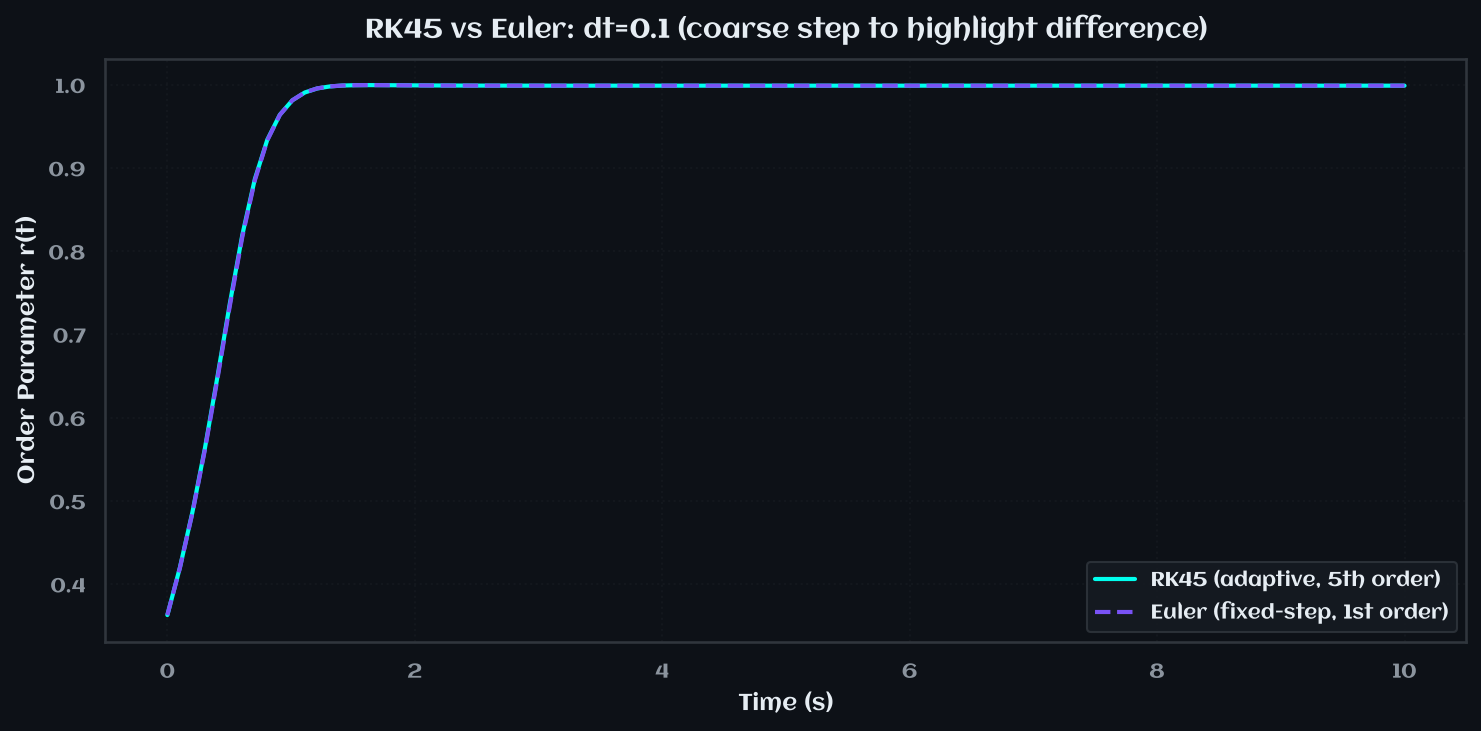

📊 Phase difference (RK45 vs Euler):
   Max absolute difference: 12.566371 radians
   Mean absolute difference: 5.805863 radians

💡 With a finer dt, Euler converges toward RK45 — but needs ~100× more steps for the same accuracy.


In [4]:
# Demonstrate the difference between Euler and RK45 on the same problem
# We'll use a coarse dt to make the difference visible

N = 5
omega = np.array([1.0, 1.2, 0.8, 1.1, 0.9])
K = 3.0
timesteps = 100
dt_coarse = 0.1  # Deliberately coarse to show Euler's limitations

# RK45 solver (adaptive, high accuracy)
ds_rk45 = generate_kuramoto_dataset(
    n_oscillators=N, natural_frequencies=omega, coupling=K,
    timesteps=timesteps, dt=dt_coarse, seed=42, solver="rk45",
)

# Rotor solver with Euler method (fixed-step, lower accuracy)
ds_euler = generate_kuramoto_dataset(
    n_oscillators=N, natural_frequencies=omega, coupling=K,
    timesteps=timesteps, dt=dt_coarse, seed=42, solver="euler",
)

r_rk45 = compute_order_parameter(ds_rk45["theta"])
r_euler = compute_order_parameter(ds_euler["theta"])

# Compare the order parameter trajectories
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ds_rk45["time"], r_rk45, label="RK45 (adaptive, 5th order)", 
        color=SOLVER_COLORS["rk45"], linewidth=2)
ax.plot(ds_euler["time"], r_euler, label="Euler (fixed-step, 1st order)", 
        color=SOLVER_COLORS["euler"], linewidth=2, linestyle="--")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Order Parameter r(t)")
ax.set_title(f"RK45 vs Euler: dt={dt_coarse} (coarse step to highlight difference)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Quantitative comparison
max_diff = np.max(np.abs(ds_rk45["theta"] - ds_euler["theta"]))
mean_diff = np.mean(np.abs(ds_rk45["theta"] - ds_euler["theta"]))
print(f"📊 Phase difference (RK45 vs Euler):")
print(f"   Max absolute difference: {max_diff:.6f} radians")
print(f"   Mean absolute difference: {mean_diff:.6f} radians")
print(f"\n💡 With a finer dt, Euler converges toward RK45 — but needs ~100× more steps for the same accuracy.")

## 4️⃣ Geometric Algebra — Rotors and the Cl(2,0) Even-Subalgebra

### 📖 Educational Note

**Geometric Algebra (GA)** unifies vectors, complex numbers, quaternions, and matrices into a single algebraic framework. The Kuramoto rotor solver uses GA to represent each oscillator's phase as a **rotor** — a geometric object that encodes a rotation.

#### What is Cl(2,0)?
The notation $\operatorname{Cl}_{p,q}(\mathbb{R})$ defines a Clifford algebra with:
- $p$ basis vectors that square to $+1$ (positive signature)
- $q$ basis vectors that square to $-1$ (negative signature)

For $\operatorname{Cl}_{2,0}(\mathbb{R})$:
- Two basis vectors $e_1, e_2$ with $e_1^2 = e_2^2 = +1$
- Their **geometric product** $e_1 e_2$ produces a **bivector** (a directed plane element)
- This bivector $I = e_1 e_2$ satisfies $I^2 = -1$ — it behaves exactly like the imaginary unit $i$

#### The Even-Subalgebra
The **even subalgebra** of $\operatorname{Cl}_{2,0}$ contains only scalar + bivector elements:
$$R = a + b \cdot e_1 e_2$$
This is **isomorphic to the complex numbers** $\mathbb{C}$, where $a$ is the real part and $b \cdot e_1 e_2$ plays the role of the imaginary part.

#### Rotors as Phase Representations
A rotor representing phase $\theta$ is:
$$R = \exp\left(-\frac{e_1 e_2 \cdot \theta}{2}\right) = \cos\left(\frac{\theta}{2}\right) - e_1 e_2 \cdot \sin\left(\frac{\theta}{2}\right)$$

To extract the physical phase from a rotor:
$$\theta = 2 \cdot \operatorname{atan2}\left([R]_{e_1e_2}, [R]_{\text{scalar}}\right)$$

#### Why Use GA?
1. **Composition**: Rotors compose via the geometric product — no matrix multiplication needed
2. **Generalization**: The same formalism extends to 3D rotations (quaternions) and higher dimensions
3. **Invariants**: GA makes geometric invariants (like rotor norm) naturally visible
4. **Lie Symmetry**: The $\operatorname{U}(1)$ phase symmetry of Kuramoto is built into the rotor structure

#### The RotorSolver Variants
The codebase provides several Euler stepping methods within `RotorSolver`:
- **`fast`** (default): Vectorized order-parameter-based Euler — fastest
- **`standard`** (aka `euler`): Pairwise coupling Euler — matches the textbook equation
- **`geometric`** (aka `euler_geometric`): Pure GA bivector torque — stays entirely in GA
- **`vectorized_geometric`**: Vectorized version of the geometric method

In [5]:
# Demonstrate the geometric algebra rotor representation
if CLIFFORD_AVAILABLE:
    from clifford import Cl

    # Create the Cl(2,0) algebra
    print("🔧 Building Cl(2,0) geometric algebra...")
    layout, blades = Cl(2, 0)  # 2 positive-signature basis vectors
    
    e1, e2 = blades['e1'], blades['e2']
    e12 = e1 ^ e2  # bivector (outer product) — the rotation plane
    
    # In Cl(2,0), the .value array layout is: [scalar, e1, e2, e12]
    # So .value[0] = scalar part, .value[3] = e12 bivector coefficient
    print(f"\n📐 Basis vectors:")
    print(f"   e1² = {float((e1*e1).value[0])}  (should be +1)")
    print(f"   e2² = {float((e2*e2).value[0])}  (should be +1)")
    print(f"   e12 = e1∧e2 (bivector, the rotation plane)")
    print(f"   e12² = {float((e12*e12).value[0]):.6f}  (should be -1, like imaginary unit i)")
    
    # Create a rotor for a specific phase
    theta = np.pi / 4  # 45 degrees
    
    # Rotor = exp(-e12 * theta / 2)
    # Using the half-angle formula: R = cos(theta/2) - e12 * sin(theta/2)
    R = np.cos(theta / 2) - e12 * np.sin(theta / 2)
    
    # Find the bivector index in the .value array (e12 is at index 3 in Cl(2,0))
    b_idx = None
    for i, v in enumerate(e12.value):
        if v != 0:
            b_idx = i
            break
    
    print(f"\n🔄 Rotor for θ = {theta:.4f} rad ({np.degrees(theta):.1f}°):")
    print(f"   R = {R}")
    print(f"   Scalar part: {float(R.value[0]):.6f}  (cos(θ/2) = {np.cos(theta/2):.6f})")
    
    # Extract phase back from the rotor
    # The bivector coefficient is -sin(theta/2), stored at .value[b_idx]
    bivector_coeff = float(R.value[b_idx])
    scalar_part = float(R.value[0])
    theta_extracted = 2 * np.arctan2(-bivector_coeff, scalar_part)
    
    print(f"   Bivector coeff: {bivector_coeff:.6f}  (-sin(θ/2) = {-np.sin(theta/2):.6f})")
    print(f"   Extracted θ: {theta_extracted:.6f} rad (original: {theta:.6f})")
    print(f"   Round-trip error: {abs(theta - theta_extracted):.2e}")
    
    # Demonstrate rotor norm preservation (key invariant)
    # abs(R) computes sqrt((R * R.conjugate()).scalar()) — should be 1 for unit rotors
    norm_R = abs(R)
    print(f"\n📏 Rotor norm invariant: |R| = {norm_R:.10f}  (should be 1.0)")
    print(f"   This is the GA equivalent of |e^(iθ)| = 1 for complex numbers")
    
    # Show rotation action: R v R.conjugate() rotates vector v by angle theta
    v = e1  # unit vector along x-axis
    v_rotated = R * v * R.conjugate()  # rotate v by the rotor
    
    print(f"\n🔄 Rotation action: R · e1 · R.conjugate()")
    print(f"   Original vector: e1 = (1, 0)")
    x_new = float(v_rotated.value[1])  # e1 component is at index 1
    y_new = float(v_rotated.value[2])  # e2 component is at index 2
    print(f"   Rotated vector: ({x_new:.6f}, {y_new:.6f})")
    print(f"   Expected: (cos(θ), sin(θ)) = ({np.cos(theta):.6f}, {np.sin(theta):.6f})")
    
else:
    print("⚠️  Clifford not available — skipping GA demonstration")

🔧 Building Cl(2,0) geometric algebra...

📐 Basis vectors:
   e1² = 1.0  (should be +1)
   e2² = 1.0  (should be +1)
   e12 = e1∧e2 (bivector, the rotation plane)
   e12² = -1.000000  (should be -1, like imaginary unit i)

🔄 Rotor for θ = 0.7854 rad (45.0°):
   R = 0.92388 - (0.38268^e12)
   Scalar part: 0.923880  (cos(θ/2) = 0.923880)
   Bivector coeff: -0.382683  (-sin(θ/2) = -0.382683)
   Extracted θ: 0.785398 rad (original: 0.785398)
   Round-trip error: 1.11e-16

📏 Rotor norm invariant: |R| = 1.0000000000  (should be 1.0)
   This is the GA equivalent of |e^(iθ)| = 1 for complex numbers

🔄 Rotation action: R · e1 · R.conjugate()
   Original vector: e1 = (1, 0)
   Rotated vector: (0.707107, 0.707107)
   Expected: (cos(θ), sin(θ)) = (0.707107, 0.707107)


/var/folders/ns/5plm23416m58x94bms_cdd9r0000gn/T/ipykernel_603/2982300066.py:53: UserWarning: Glyph 952 (\N{GREEK SMALL LETTER THETA}) missing from font(s) Aclonica.
  plt.tight_layout()
/var/folders/ns/5plm23416m58x94bms_cdd9r0000gn/T/ipykernel_603/2982300066.py:53: UserWarning: Glyph 8214 (\N{DOUBLE VERTICAL LINE}) missing from font(s) Aclonica.
  plt.tight_layout()
/Users/lshriver/PycharmProjects/kuramoto-benchmark-suite/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 952 (\N{GREEK SMALL LETTER THETA}) missing from font(s) Aclonica.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/lshriver/PycharmProjects/kuramoto-benchmark-suite/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8214 (\N{DOUBLE VERTICAL LINE}) missing from font(s) Aclonica.
  fig.canvas.print_figure(bytes_io, **kw)


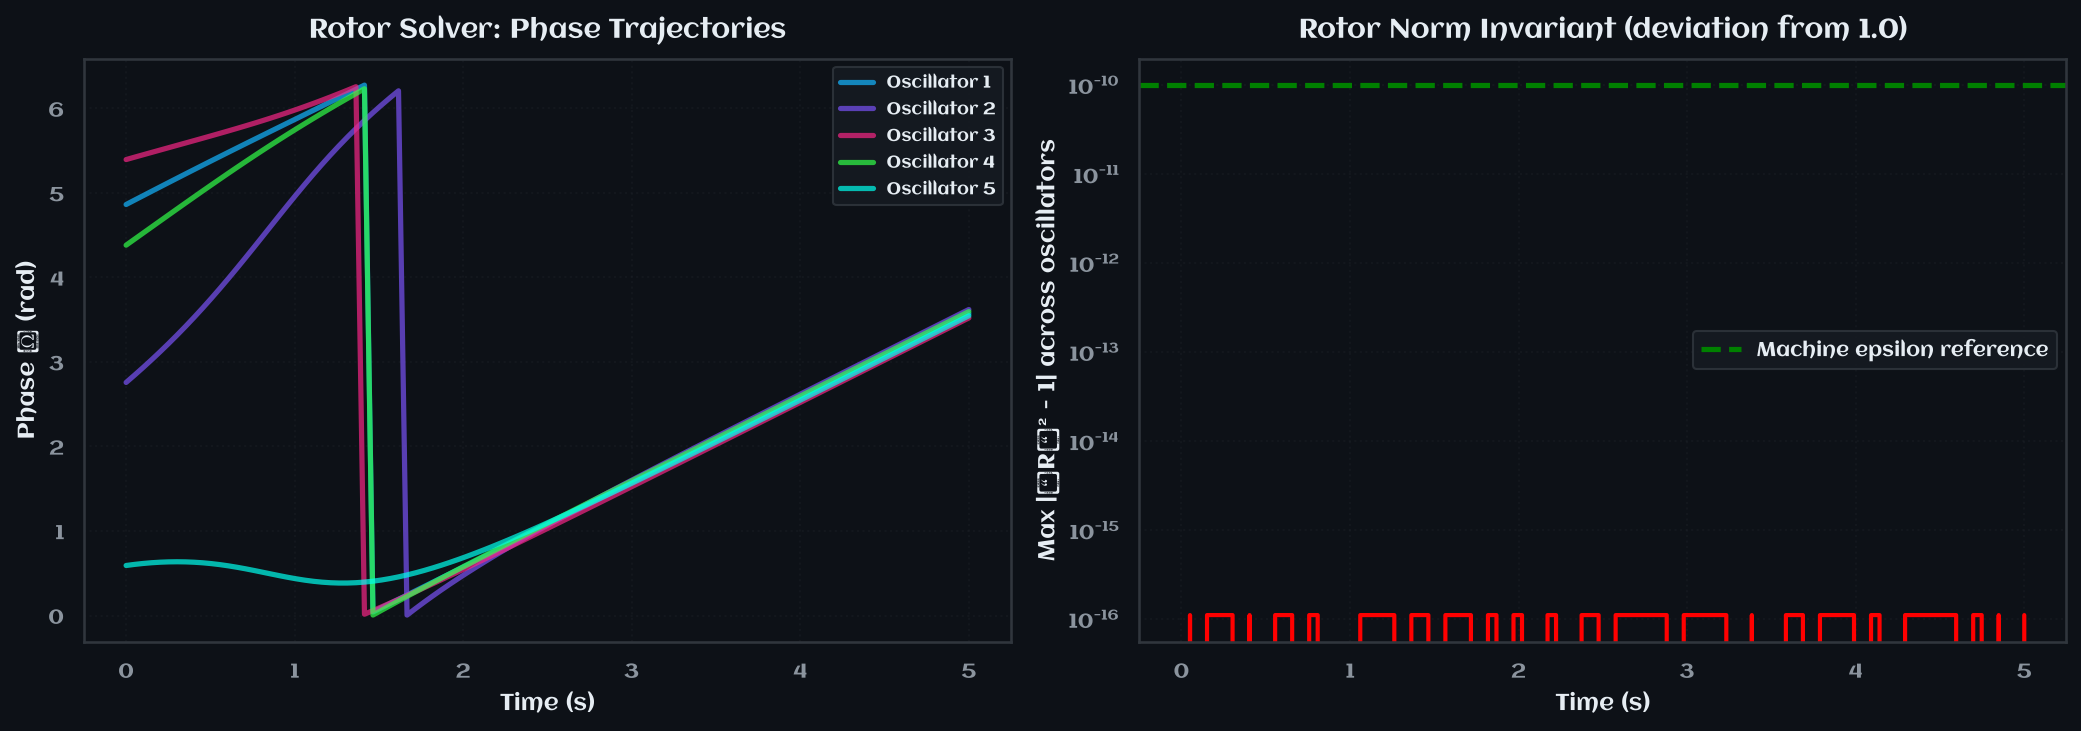

📏 Rotor norm invariant check:
   Max deviation from 1.0: 1.11e-16
   Mean deviation: 7.44e-17
   ✅ Norms preserved to machine precision

📈 Order parameter (rotor solver):
   Final r: 0.9994
   Mean r:  0.9075


In [6]:
# Demonstrate rotor norm preservation during simulation
# This is a key invariant: rotors must remain unit rotors throughout integration

if CLIFFORD_AVAILABLE:
    N = 5
    omega = np.array([1.0, 1.1, 0.9, 1.05, 0.95])
    K = 2.0
    t_eval = np.linspace(0, 5.0, 100)
    
    solver = RotorSolver(n_oscillators=N, dim=2, seed=42)
    solver.omegas = omega
    
    times, phases = solver.simulate(
        K=K, t_eval=t_eval, dt_internal=0.001, 
        enforce_nyquist=True, method="fast"
    )
    
    # Check rotor norms at each time step
    norms = []
    for i in range(len(times)):
        # Reconstruct rotors from phases to check norm
        max_norm_deviation = 0.0
        for j in range(N):
            theta_j = phases[i, j]
            R_j = np.cos(theta_j / 2) - solver.blades['e12'] * np.sin(theta_j / 2)
            norm_j = abs(R_j)  # |R| should be 1.0 for unit rotors
            max_norm_deviation = max(max_norm_deviation, abs(norm_j - 1.0))
        norms.append(max_norm_deviation)
    
    norms = np.array(norms)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Left: Phase trajectories
    for j in range(N):
        axes[0].plot(times, phases[:, j], alpha=0.7, label=f"Oscillator {j+1}")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Phase θ (rad)")
    axes[0].set_title("Rotor Solver: Phase Trajectories")
    axes[0].legend(fontsize=8)
    axes[0].grid(True, alpha=0.3)
    
    # Right: Norm deviation (should be near zero)
    axes[1].plot(times, norms, color='red', linewidth=2)
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Max |‖R‖² - 1| across oscillators")
    axes[1].set_title("Rotor Norm Invariant (deviation from 1.0)")
    axes[1].set_yscale('log')
    axes[1].axhline(y=1e-10, color='green', linestyle='--', label='Machine epsilon reference')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print(f"📏 Rotor norm invariant check:")
    print(f"   Max deviation from 1.0: {norms.max():.2e}")
    print(f"   Mean deviation: {norms.mean():.2e}")
    print(f"   ✅ Norms preserved to machine precision" if norms.max() < 1e-10 else "   ⚠️  Some norm drift detected")
    
    # Order parameter from rotor solver
    r_rotor = compute_order_parameter(phases)
    print(f"\n📈 Order parameter (rotor solver):")
    print(f"   Final r: {r_rotor[-1]:.4f}")
    print(f"   Mean r:  {r_rotor.mean():.4f}")
    
else:
    print("⚠️  Clifford not available — skipping rotor invariant demonstration")

## 5️⃣ Solver Comparison — All Methods Side-by-Side

### 📖 Educational Note

The Kuramoto suite provides multiple solver backends. Let's run them all on the same problem and compare:

| Solver | Method | Integration | Notes |
|--------|--------|-------------|-------|
| `rk45` | Runge-Kutta 4(5) | Adaptive | SciPy's `solve_ivp`, gold standard for accuracy |
| `euler` | Fixed-step Euler | Pairwise | Textbook implementation, $O(N^2)$ per step |
| `euler_fast` | Fixed-step Euler | Order-param | Uses mean-field approximation, $O(N)$ per step |
| `euler_geometric` | Fixed-step Euler | GA bivector | Pure geometric algebra torque |
| `rotor` | Alias for rotor solver | Various | Default method is 'fast' |

The `generate_kuramoto_dataset()` API abstracts all of these behind a single `solver=` parameter.

⏱️  Running solver comparison...

  rk45                 | final r=0.9987 | time=  38.6ms
  euler                | final r=0.9987 | time= 562.5ms
  euler_fast           | final r=0.9987 | time=  49.7ms
  rotor                | final r=0.9987 | time=  20.0ms
  euler_geometric      | final r=0.9987 | time=  23.3ms


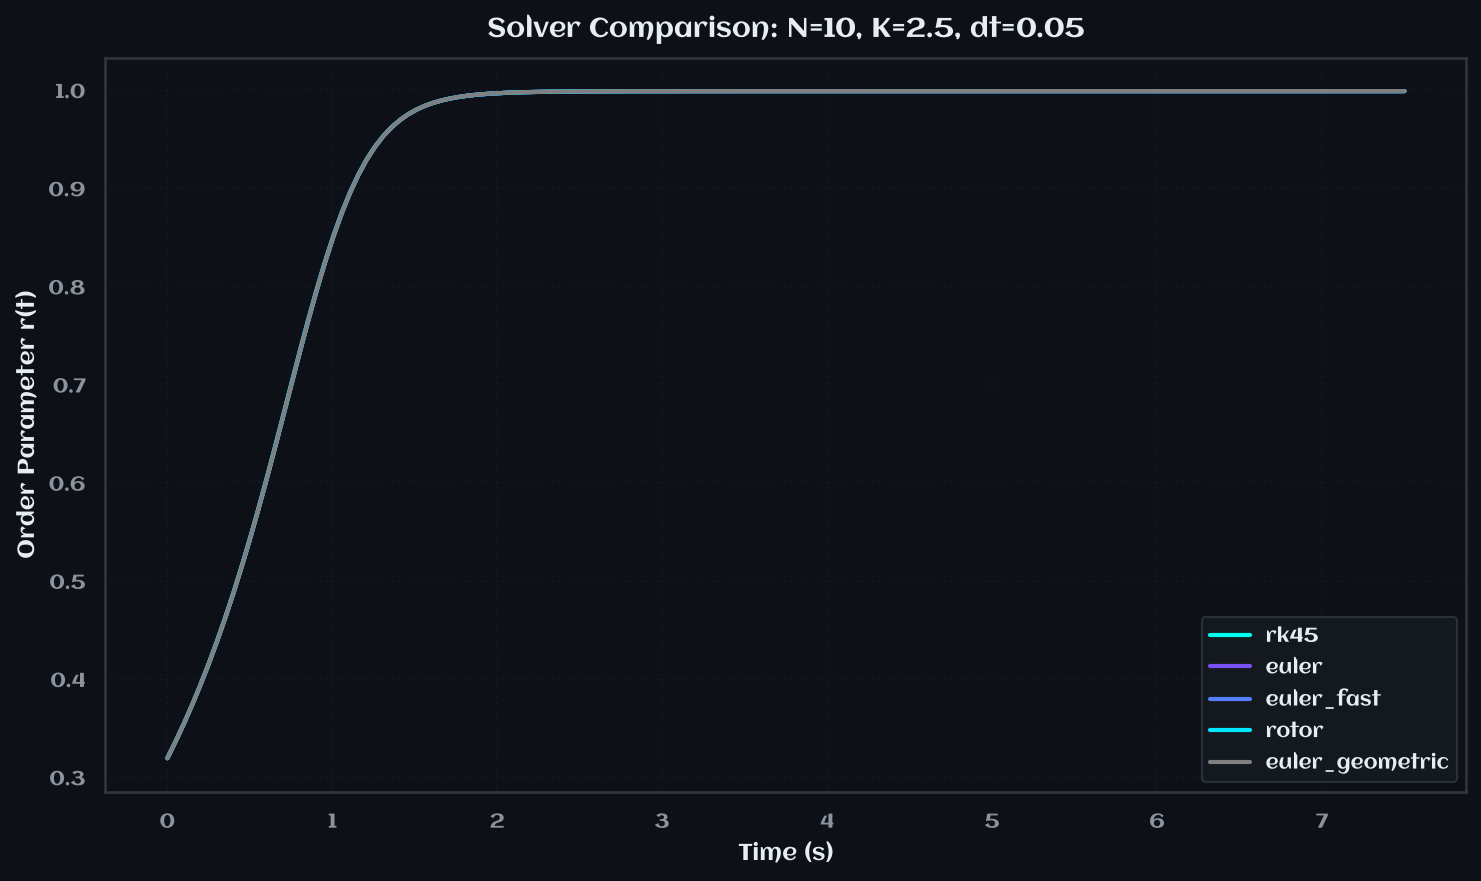


📊 Timing Summary:
╭─────────────────┬─────────────┬──────────────╮
│ Solver          │ Wall Time   │   Final r(t) │
├─────────────────┼─────────────┼──────────────┤
│ rk45            │ 38.6ms      │       0.9987 │
├─────────────────┼─────────────┼──────────────┤
│ euler           │ 562.5ms     │       0.9987 │
├─────────────────┼─────────────┼──────────────┤
│ euler_fast      │ 49.7ms      │       0.9987 │
├─────────────────┼─────────────┼──────────────┤
│ rotor           │ 20.0ms      │       0.9987 │
├─────────────────┼─────────────┼──────────────┤
│ euler_geometric │ 23.3ms      │       0.9987 │
╰─────────────────┴─────────────┴──────────────╯


In [7]:
# Run all available solver types and compare their order parameter trajectories
import time

N = 10
omega = np.linspace(0.8, 1.2, N)  # spread frequencies
K = 2.5
timesteps = 150
dt = 0.05

# Solvers to compare
solver_names = ["rk45", "euler", "euler_fast"]
if CLIFFORD_AVAILABLE:
    solver_names.extend(["rotor", "euler_geometric"])

results = {}
timings = {}

print("⏱️  Running solver comparison...\n")
for sname in solver_names:
    t0 = time.perf_counter()
    ds = generate_kuramoto_dataset(
        n_oscillators=N, natural_frequencies=omega, coupling=K,
        timesteps=timesteps, dt=dt, seed=42, solver=sname,
    )
    elapsed = time.perf_counter() - t0
    results[sname] = ds
    timings[sname] = elapsed
    r = compute_order_parameter(ds["theta"])
    print(f"  {sname:20s} | final r={r[-1]:.4f} | time={elapsed*1000:6.1f}ms")

# Plot all order parameter trajectories
fig, ax = plt.subplots(figsize=(10, 6))
for sname in solver_names:
    ds = results[sname]
    r = compute_order_parameter(ds["theta"])
    color = SOLVER_COLORS.get(sname, 'gray')
    ax.plot(ds["time"], r, label=sname, color=color, linewidth=2)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Order Parameter r(t)")
ax.set_title(f"Solver Comparison: N={N}, K={K}, dt={dt}")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Timing comparison
print("\n📊 Timing Summary:")
print(tabulate(
    [[s, f"{timings[s]*1000:.1f}ms", f"{compute_order_parameter(results[s]['theta'])[-1]:.4f}"] 
     for s in solver_names],
    headers=["Solver", "Wall Time", "Final r(t)"],
    tablefmt="rounded_grid"
))

## 6️⃣ Order Parameter — Measuring Synchronization

### 📖 Educational Note

The **Kuramoto order parameter** is the central diagnostic of synchronization:

$$r(t) e^{i\psi(t)} = \frac{1}{N} \sum_{j=1}^{N} e^{i\theta_j(t)}$$

This is a **complex number** whose:
- **Magnitude** $r(t) \in [0, 1]$ measures the degree of phase coherence
- **Angle** $\psi(t)$ gives the mean phase of the population

#### Interpretation
| $r(t)$ value | Meaning |
|--------------|---------|
| $r \approx 1.0$ | All oscillators locked in phase (perfect sync) |
| $r \approx 0.5$ | Partial synchronization — a cluster is locked |
| $r \approx 0.0$ | Phases uniformly distributed (incoherent) |

#### Autocorrelation
The **autocorrelation** of $r(t)$ measures how long the synchronization state "remembers" itself. A slow decay indicates persistent synchronization; a fast decay indicates fluctuating sync.

#### Lie Symmetry (U(1) Phase Invariance)
The Kuramoto equations are invariant under a global phase shift:
$$\theta_i(t) \rightarrow \theta_i(t) + \phi \quad \text{for all } i$$
This $\operatorname{U}(1)$ symmetry is a fundamental property that the rotor solver preserves by construction.

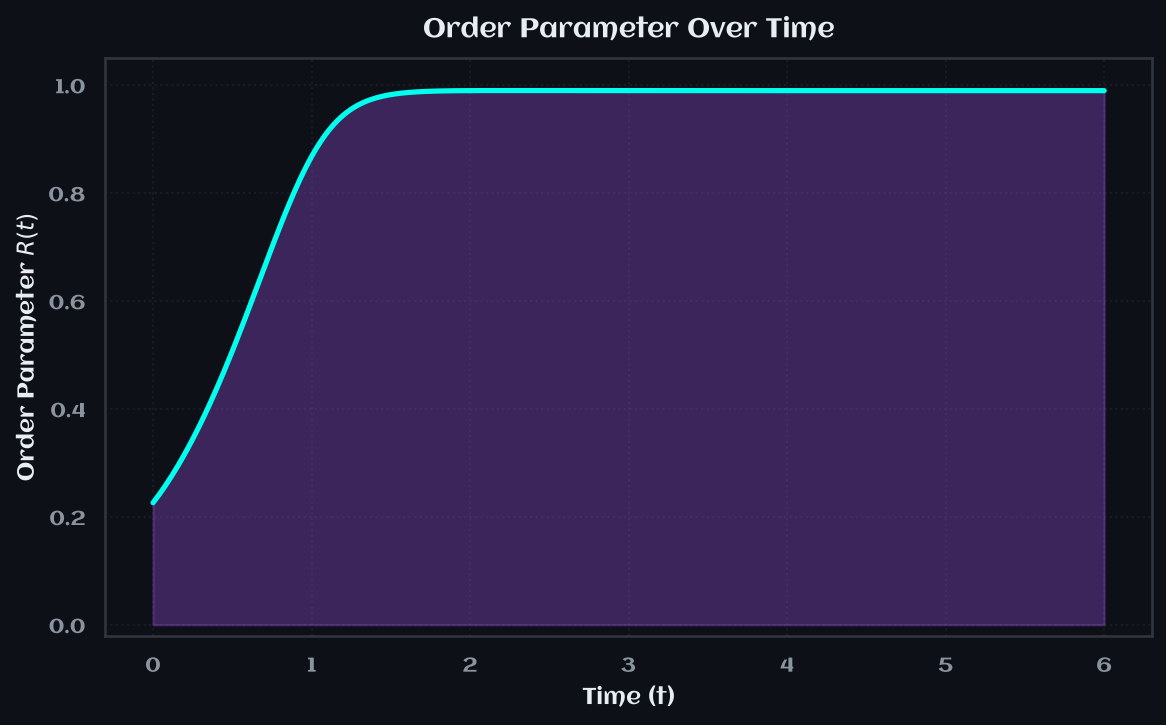

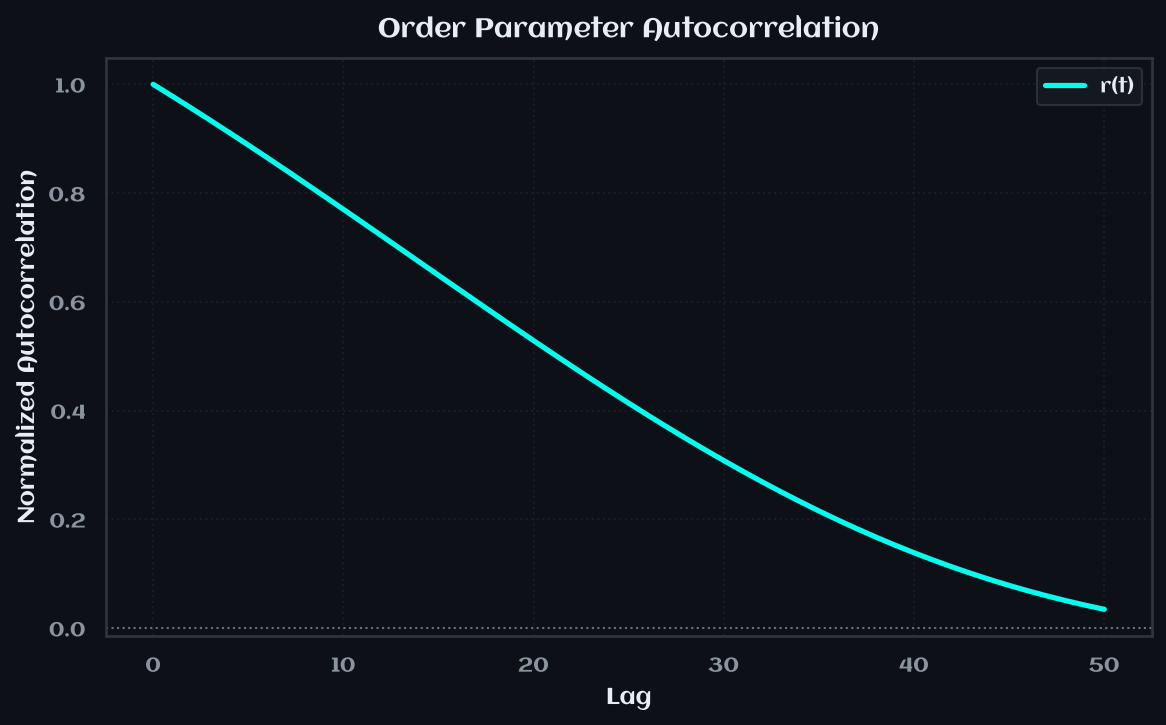

📈 Order parameter statistics:
   r[0] = 0.2261 (initial)
   r[-1] = 0.9897 (final)
   r_mean = 0.9071
   r_std = 0.1921

📊 Autocorrelation at lag 0: 1.0000 (should be 1.0)
   Autocorrelation at lag 10: 0.7701
   (Slower decay = more persistent synchronization)


In [8]:
# Generate a dataset that shows the synchronization transition
N = 20
omega = np.random.default_rng(42).normal(1.0, 0.5, N)  # broader spread
K = 3.0
timesteps = 300
dt = 0.02

ds = generate_kuramoto_dataset(
    n_oscillators=N, natural_frequencies=omega, coupling=K,
    timesteps=timesteps, dt=dt, seed=42, solver="rk45",
)

theta = ds["theta"]
times = ds["time"]
r = compute_order_parameter(theta)

# Plot the order parameter (creates its own figure)
plot_order_parameter(times, r)

# Compute and plot autocorrelation
lags, autocorr = compute_order_parameter_autocorrelation(r, max_lag=50)
# plot_autocorrelation expects a Dict[str, Tuple[lags, autocorr]]
plot_autocorrelation({"r(t)": (lags, autocorr)})

print(f"📈 Order parameter statistics:")
print(f"   r[0] = {r[0]:.4f} (initial)")
print(f"   r[-1] = {r[-1]:.4f} (final)")
print(f"   r_mean = {r.mean():.4f}")
print(f"   r_std = {r.std():.4f}")
print(f"\n📊 Autocorrelation at lag 0: {autocorr[0]:.4f} (should be 1.0)")
print(f"   Autocorrelation at lag 10: {autocorr[10]:.4f}")
print(f"   (Slower decay = more persistent synchronization)")

In [9]:
# Demonstrate Lie symmetry tracking (only available for rotor/Euler solvers)
if CLIFFORD_AVAILABLE:
    N = 10
    omega = np.ones(N) * 1.0
    K = 2.0
    timesteps = 100
    dt = 0.05

    ds = generate_kuramoto_dataset(
        n_oscillators=N, natural_frequencies=omega, coupling=K,
        timesteps=timesteps, dt=dt, seed=42, solver="rotor",
        symmetry_metrics=True,
    )

    print("🔬 Lie Symmetry Diagnostics (rotor solver):")
    print(f"   U(1) phase invariant: {ds.get('global_phase_invariant', 'N/A')}")
    print(f"   Synchronization strength: {ds.get('synchronization_strength', 'N/A'):.4f}")
    
    if 'energy_conserved' in ds:
        energy = ds['energy_conserved']
        print(f"   Energy trajectory: min={energy.min():.4f}, max={energy.max():.4f}")
        print(f"   Energy drift: {energy[-1] - energy[0]:.6f}")
    
    print(f"\n💡 The U(1) symmetry means the equations are unchanged if we shift")
    print(f"   all phases by the same constant. The rotor representation preserves")
    print(f"   this symmetry by construction — it's built into the GA structure.")
else:
    print("⚠️  Clifford not available — Lie symmetry tracking requires rotor solver")

🔬 Lie Symmetry Diagnostics (rotor solver):
   U(1) phase invariant: True
   Synchronization strength: 1.0000
   Energy trajectory: min=-0.5000, max=561.8160
   Energy drift: -0.990057

💡 The U(1) symmetry means the equations are unchanged if we shift
   all phases by the same constant. The rotor representation preserves
   this symmetry by construction — it's built into the GA structure.


## 7️⃣ Spectral Analysis — Fourier and PSD

### 📖 Educational Note

Spectral analysis reveals the **frequency content** of the synchronization signal:

#### Fourier Coefficients
Any periodic signal can be decomposed into sine/cosine components:
$$f(t) = \sum_{k=-\infty}^{\infty} c_k e^{ik\omega_0 t}$$
The coefficients $c_k$ tell us which harmonics (multiples of the fundamental frequency) are present.

#### Power Spectral Density (PSD)
The PSD shows how the signal's power is distributed across frequencies. A sharp peak at the synchronization frequency indicates coherent oscillation.

#### Harmonic Analysis
When oscillators synchronize, the order parameter $r(t)$ develops a dominant frequency component. The harmonic analysis identifies this fundamental frequency and its overtones.

#### Sync Transition Detection
By sweeping the coupling strength $K$ and monitoring the PSD, we can detect the critical $K_c$ where synchronization emerges — a **bifurcation point** in the system's dynamics.

🎵 Harmonic Analysis of Order Parameter:
   h1_power_ratio: 1.0000
   h2_power_ratio: 0.0411
   h3_power_ratio: 0.0213
   h4_power_ratio: 0.0088
   h5_power_ratio: 0.0030
   rest_ratio: -0.0742


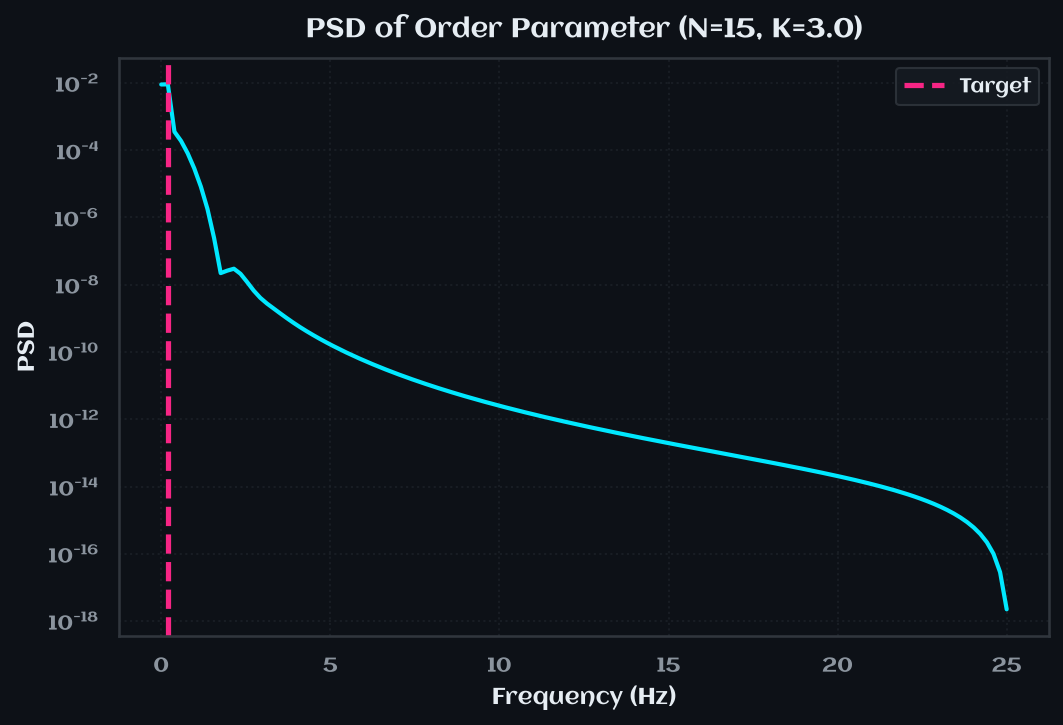


📊 Fourier coefficients shape: (15,)
   (oscillators: N=15)


In [10]:
# Spectral analysis of the order parameter
N = 15
omega = np.random.default_rng(42).normal(1.0, 0.3, N)
K = 3.0
timesteps = 500
dt = 0.02

ds = generate_kuramoto_dataset(
    n_oscillators=N, natural_frequencies=omega, coupling=K,
    timesteps=timesteps, dt=dt, seed=42, solver="rk45",
)

times = ds["time"]
r = compute_order_parameter(ds["theta"])
fs = 1.0 / dt  # sampling frequency

# Compute PSD
freqs, psd = compute_psd(r, fs)

# Harmonic analysis
harmonics = harmonic_analysis(r, dt)

print("🎵 Harmonic Analysis of Order Parameter:")
for name, ratio in harmonics.items():
    print(f"   {name}: {ratio:.4f}")

# Plot PSD (target_freq is required; use the dominant frequency)
target_freq = freqs[np.argmax(psd)]
plot_psd_variability(freqs, psd, target_freq=target_freq, title=f"PSD of Order Parameter (N={N}, K={K})")

# Fourier coefficients of individual oscillator phases
coeffs = compute_fourier_coefficients(times, ds["theta"], target_freq=target_freq)
print(f"\n📊 Fourier coefficients shape: {coeffs.shape}")
print(f"   (oscillators: N={coeffs.shape[0]})")

## 8️⃣ Visualization System — Themes, Colormaps, and Plot Functions

### 📖 Educational Note

The visualization system in `kuramoto.analysis.viz` provides:

#### Design Tokens
- **Theme colors**: Background, card, border, grid, text colors for the dark theme
- **Color palettes**: `PROJECT_COLORS`, `SOLVER_COLORS`, `COMPARISON_PALETTE`
- **Golden ratio constants**: `PHI`, `INV_PHI`, etc. — used for aesthetically pleasing layouts

#### Semantic Colormaps
8 purpose-built colormaps for different physical quantities:
- `PHASE_CMAP` — Phase angle visualization
- `ORDER_PARAMETER_CMAP` — Synchronization strength
- `SPECTRAL_DENSITY_CMAP` — Frequency domain plots
- `HAMILTONIAN_CMAP` — Energy landscapes
- And more...

#### Plot Functions
12+ specialized plotting functions for Kuramoto-specific visualizations:
- `plot_time_series` — Phase trajectories over time
- `plot_order_parameter` — Synchronization metric
- `plot_network` — Network topology visualization
- `plot_distributions` — Frequency/phase histograms
- `plot_fluid_vorticity` — Phase velocity field
- And more...

This section exercises **every** visualization function to establish a visual baseline before the planned viz refactor.

🎨 Design Tokens:
   THEME_BG:     #0d1117
   TEXT_PRIMARY: #e6edf3
   TEXT_MUTED:   #8b949e
   GOLDEN_RATIO: 1.618034  (φ = 1.618034)

🎨 PROJECT_COLORS (26 colors):
   cyan_light          : #00FFEE
   cyan_blue           : #00E8FF
   blue_light          : #14B5FF
   blue_mid            : #0A95EB
   blue_deep           : #0070EB
   indigo              : #5280FF
   indigo_blue         : #5280FF
   purple_deep         : #A855F7
   purple_light        : #7952F5
   purple_dark         : #7C5CFF
   purple_lavender     : #D8B4FE
   pink_vibrant        : #FF66B3
   pink_pink           : #F72585
   pink_dark           : #AD1457
   pink_light          : #FFB4F6
   pink_alt            : #FF40A1
   orange_warm         : #FF9D57
   orange_soft         : #F78166
   green_neon          : #31FF48
   green_lime          : #70E000
   green_light         : #57FFBC
   green_emerald       : #059669
   green_dark          : #035100
   green_jade          : #00FF7F
   cyan_green          : #00F5D4
   yellow_

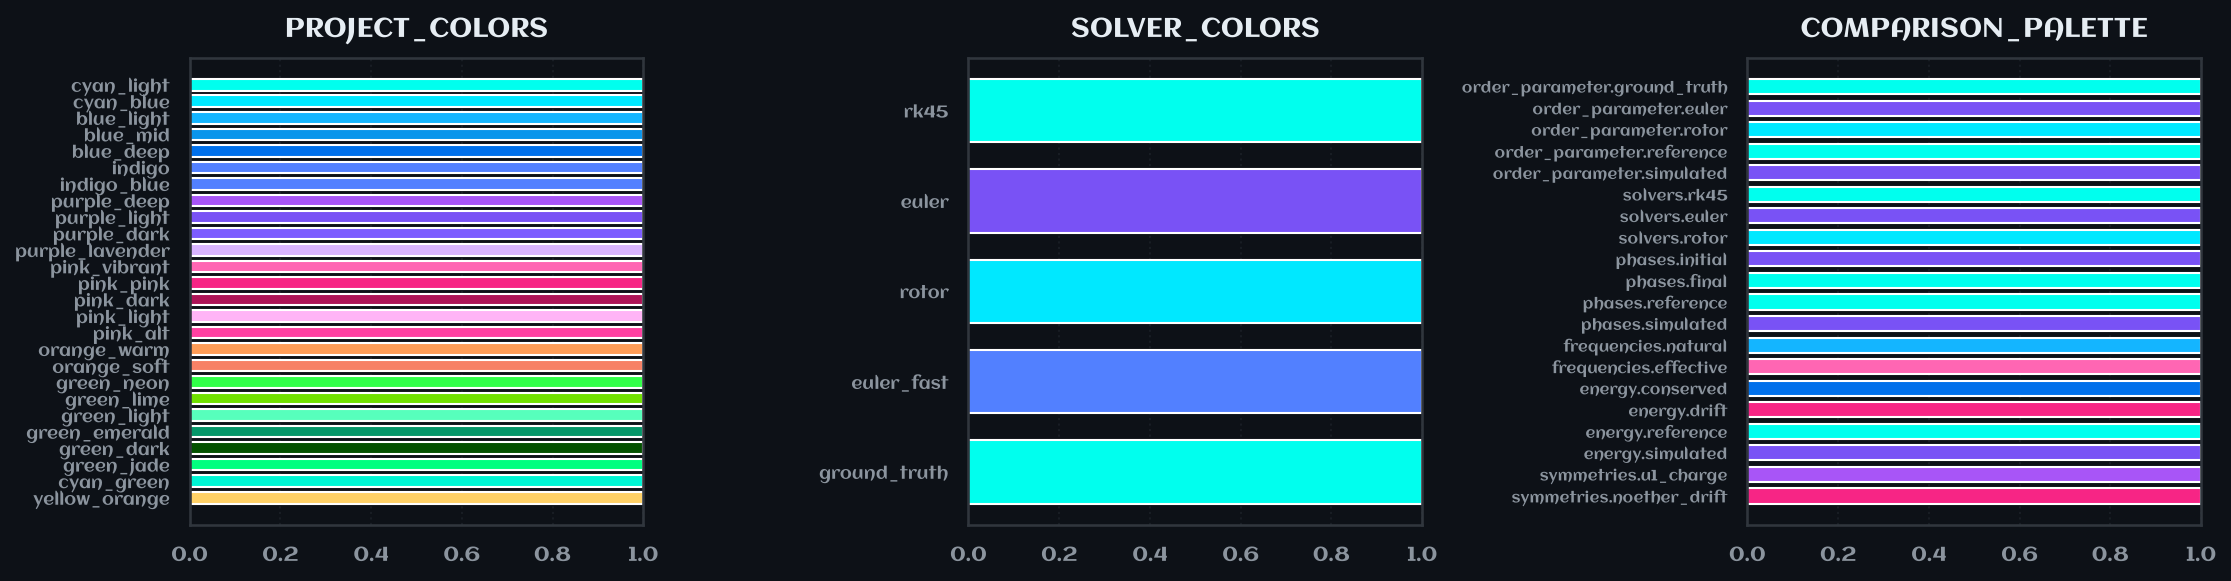

In [11]:
# Display the design tokens and color palettes
print("🎨 Design Tokens:")
print(f"   THEME_BG:     {THEME_BG}")
print(f"   TEXT_PRIMARY: {TEXT_PRIMARY}")
print(f"   TEXT_MUTED:   {TEXT_MUTED}")
print(f"   GOLDEN_RATIO: {GOLDEN_RATIO:.6f}  (φ = {PHI:.6f})")

print(f"\n🎨 PROJECT_COLORS ({len(PROJECT_COLORS)} colors):")
for name, color in PROJECT_COLORS.items():
    print(f"   {name:20s}: {color}")

print(f"\n🎨 SOLVER_COLORS ({len(SOLVER_COLORS)} colors):")
for name, color in SOLVER_COLORS.items():
    print(f"   {name:20s}: {color}")

print(f"\n🎨 COMPARISON_PALETTE:")
for category, colors in COMPARISON_PALETTE.items():
    print(f"   {category}:")
    for name, color in colors.items():
        print(f"      {name:20s}: {color}")

# Visualize the color palettes
# Flatten comparison palette items (e.g. "category / name") for bar chart display
comparison_flat = {
    f"{cat}.{name}": color
    for cat, sub in COMPARISON_PALETTE.items()
    for name, color in sub.items()
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# PROJECT_COLORS
colors = list(PROJECT_COLORS.values())
names = list(PROJECT_COLORS.keys())
for i, (name, color) in enumerate(PROJECT_COLORS.items()):
    axes[0].barh(i, 1, color=color, height=0.7)
axes[0].set_yticks(range(len(names)))
axes[0].set_yticklabels(names, fontsize=8)
axes[0].set_xlim(0, 1)
axes[0].set_title("PROJECT_COLORS")
axes[0].invert_yaxis()

# SOLVER_COLORS
for i, (name, color) in enumerate(SOLVER_COLORS.items()):
    axes[1].barh(i, 1, color=color, height=0.7)
axes[1].set_yticks(range(len(SOLVER_COLORS)))
axes[1].set_yticklabels(list(SOLVER_COLORS.keys()), fontsize=8)
axes[1].set_xlim(0, 1)
axes[1].set_title("SOLVER_COLORS")
axes[1].invert_yaxis()

# COMPARISON_PALETTE
for i, (name, color) in enumerate(comparison_flat.items()):
    axes[2].barh(i, 1, color=color, height=0.7)
axes[2].set_yticks(range(len(comparison_flat)))
axes[2].set_yticklabels(list(comparison_flat.keys()), fontsize=7)
axes[2].set_xlim(0, 1)
axes[2].set_title("COMPARISON_PALETTE")
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

🌈 Semantic Colormaps:
   phase               : phase_cyclic_gradient
   order_parameter     : order_parameter_gradient
   spectral_density    : spectral_density_gradient
   hamiltonian         : hamiltonian_gradient
   spatial_overlap     : spatial_overlap_smooth
   temporal_overlap    : spatial_overlap_smooth
   cross_overlap       : cross_overlap_diverging
   temporal            : cross_overlap_diverging


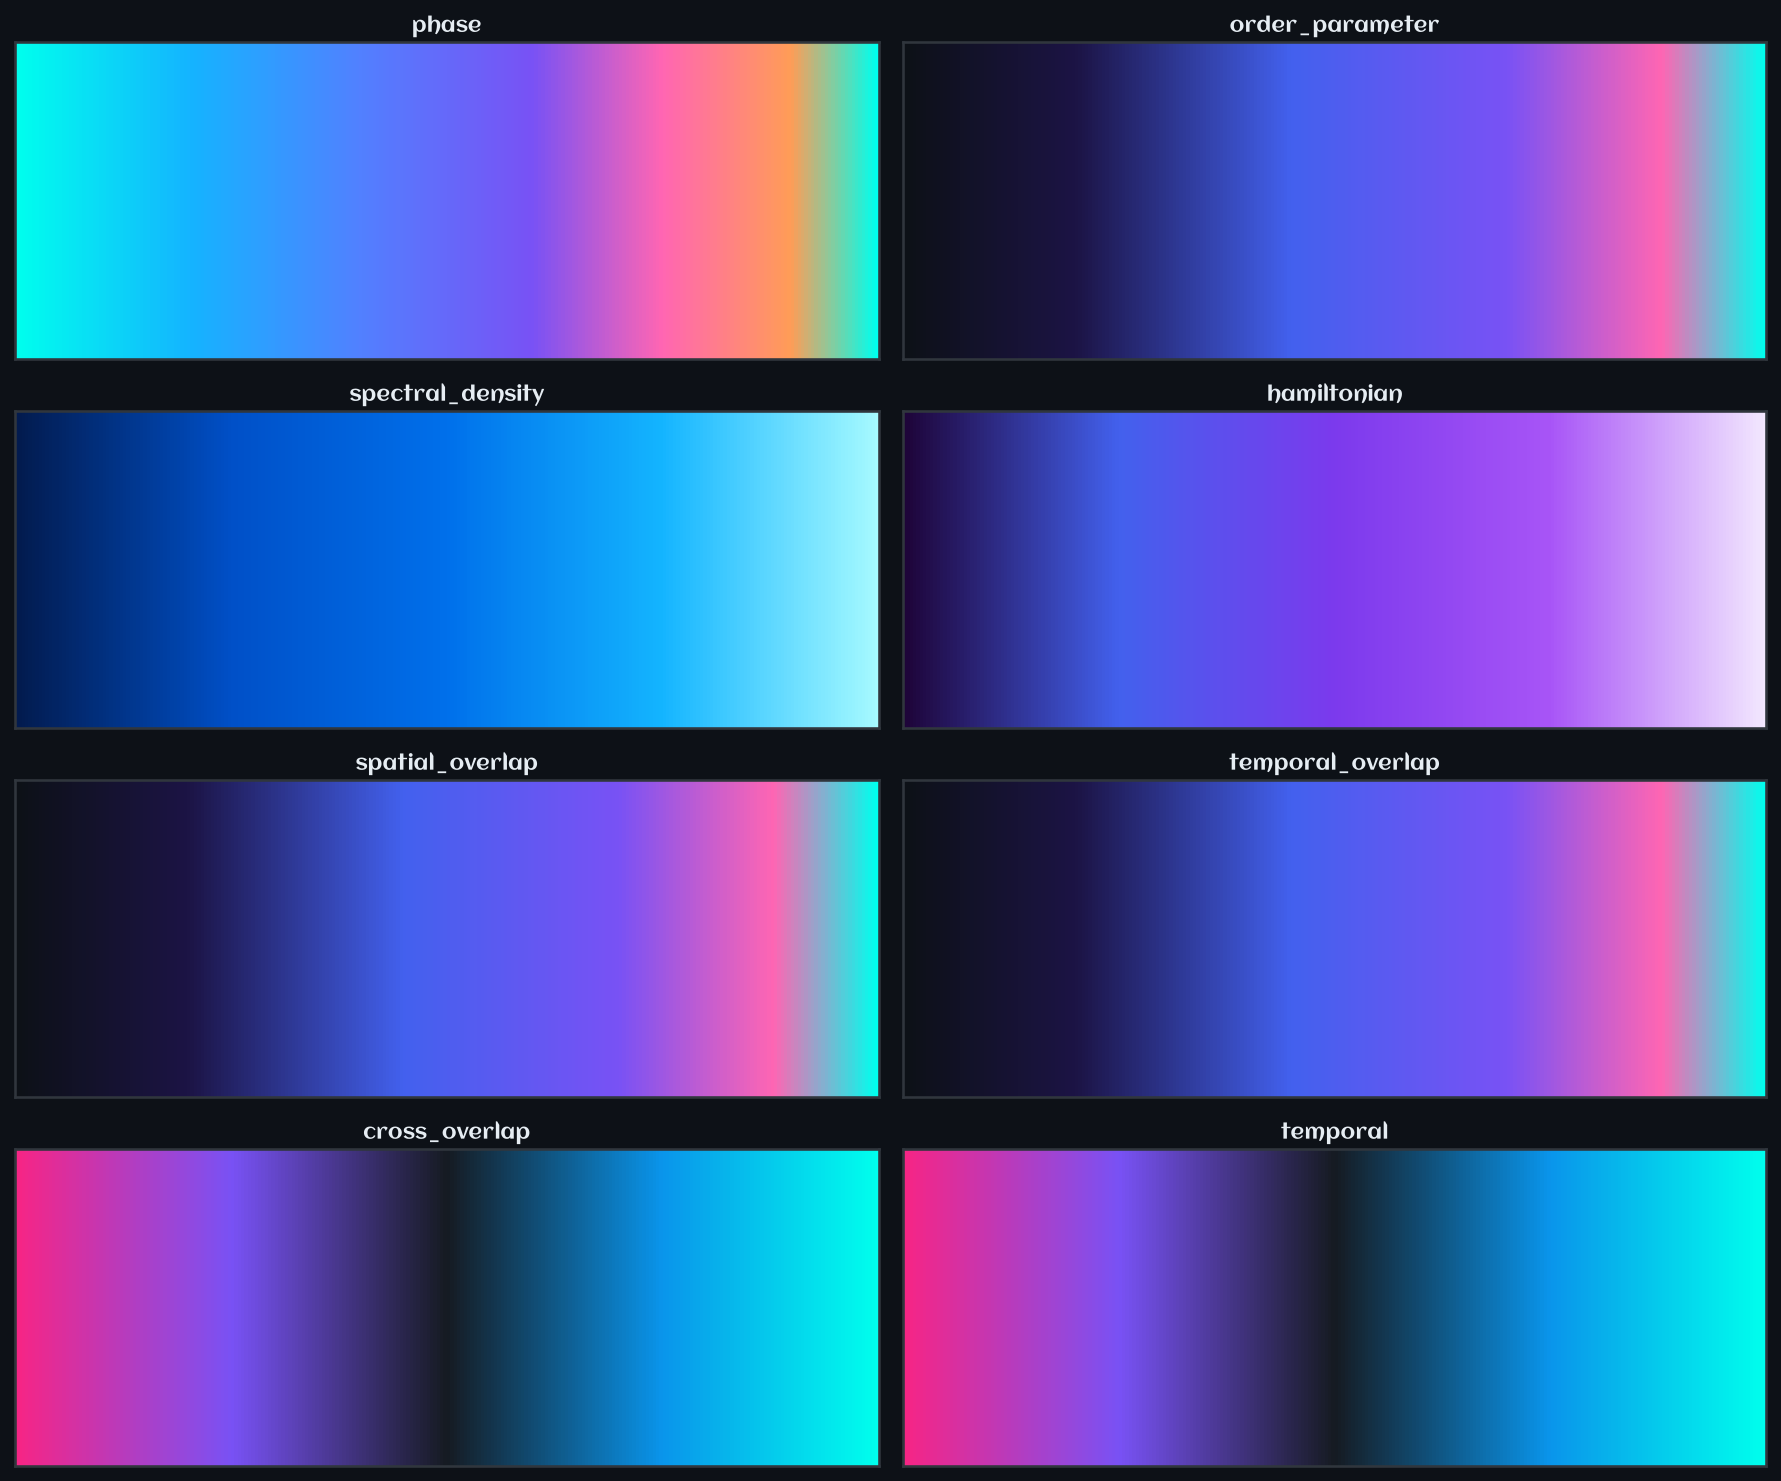


📊 GRADIENTS dictionary (15 entries):
   gradient_0: list
   gradient_1: list
   gradient_2: list
   gradient_3: list
   gradient_4: list
   gradient_5: list
   gradient_6: list
   gradient_tse: list
   phase: list
   order_parameter: list
   spectral_density: list
   hamiltonian: list
   spatial_overlap: list
   temporal_overlap: list
   cross_overlap: list


In [12]:
# Display all semantic colormaps
print("🌈 Semantic Colormaps:")
cmap_names = [
    "phase", "order_parameter", "spectral_density", "hamiltonian",
    "spatial_overlap", "temporal_overlap", "cross_overlap", "temporal"
]

for name in cmap_names:
    cmap = get_colormap(name)
    print(f"   {name:20s}: {cmap.name}")

# Render all colormaps
fig, axes = plt.subplots(4, 2, figsize=(12, 10))
axes = axes.ravel()

for i, name in enumerate(cmap_names):
    cmap = get_colormap(name)
    gradient = np.linspace(0, 1, 256)
    gradient = np.vstack((gradient, gradient))
    axes[i].imshow(gradient, aspect='auto', cmap=cmap)
    axes[i].set_title(f"{name}", fontsize=10, pad=5)
    axes[i].set_xticks([])
    axes[i].set_yticks([])

plt.tight_layout()
plt.show()

# Also show the GRADIENTS dictionary
print(f"\n📊 GRADIENTS dictionary ({len(GRADIENTS)} entries):")
for k, v in GRADIENTS.items():
    print(f"   {k}: {type(v).__name__}")

📈 Testing plot_time_series()...


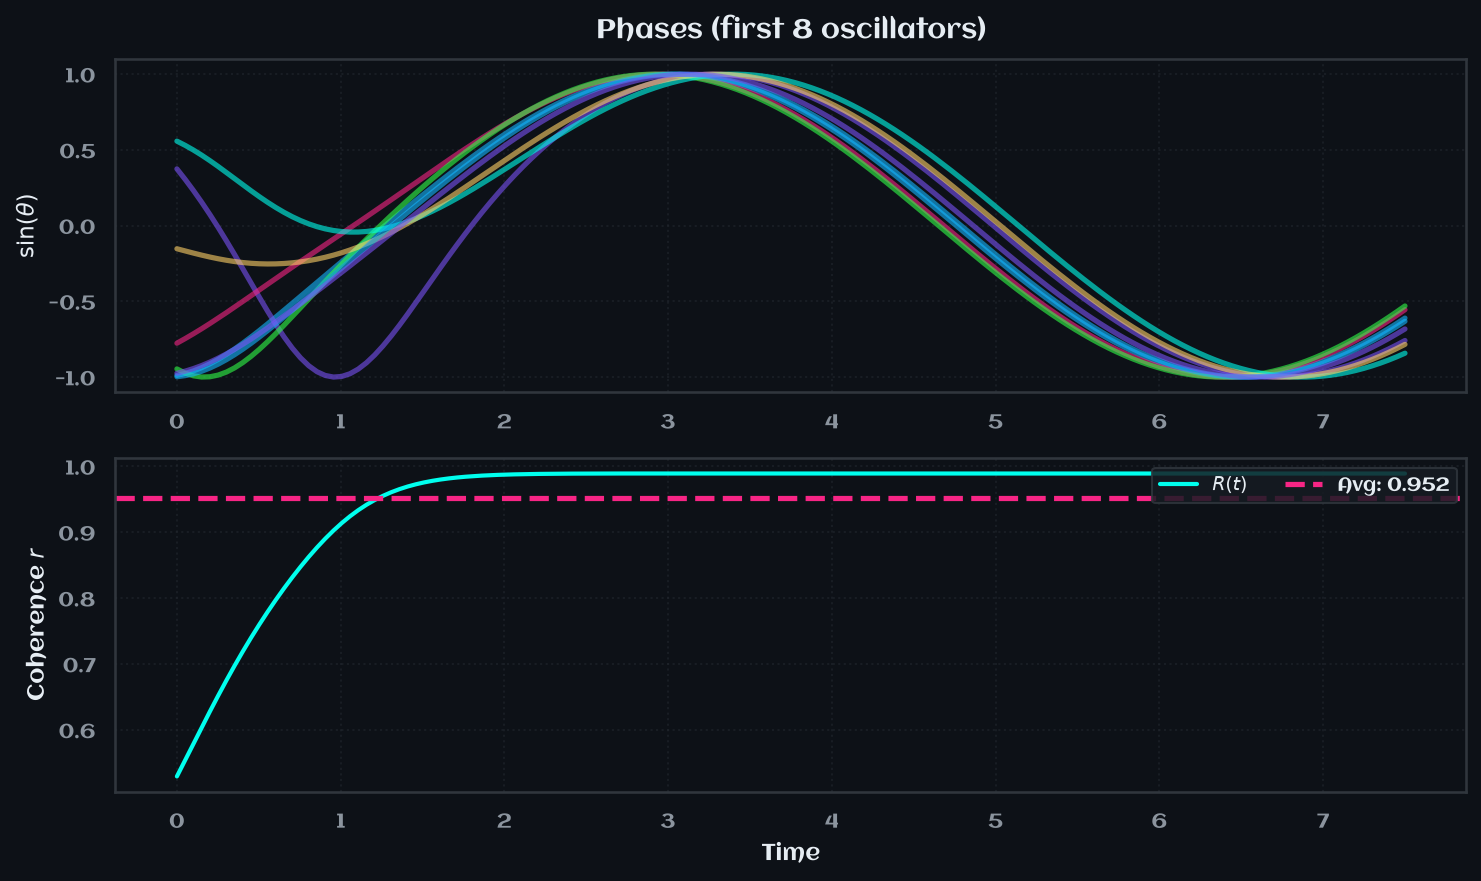

✅ plot_time_series() — passed


In [13]:
# --- plot_time_series ---
# Shows individual oscillator phase trajectories over time

print("📈 Testing plot_time_series()...")
N = 8
omega = np.random.default_rng(42).normal(1.0, 0.3, N)
ds = generate_kuramoto_dataset(
    n_oscillators=N, natural_frequencies=omega, coupling=2.0,
    timesteps=150, dt=0.05, seed=42, solver="rk45",
)

r = compute_order_parameter(ds["theta"])
plot_time_series(ds["time"], ds["theta"], r)
print("✅ plot_time_series() — passed")

📈 Testing plot_order_parameter()...


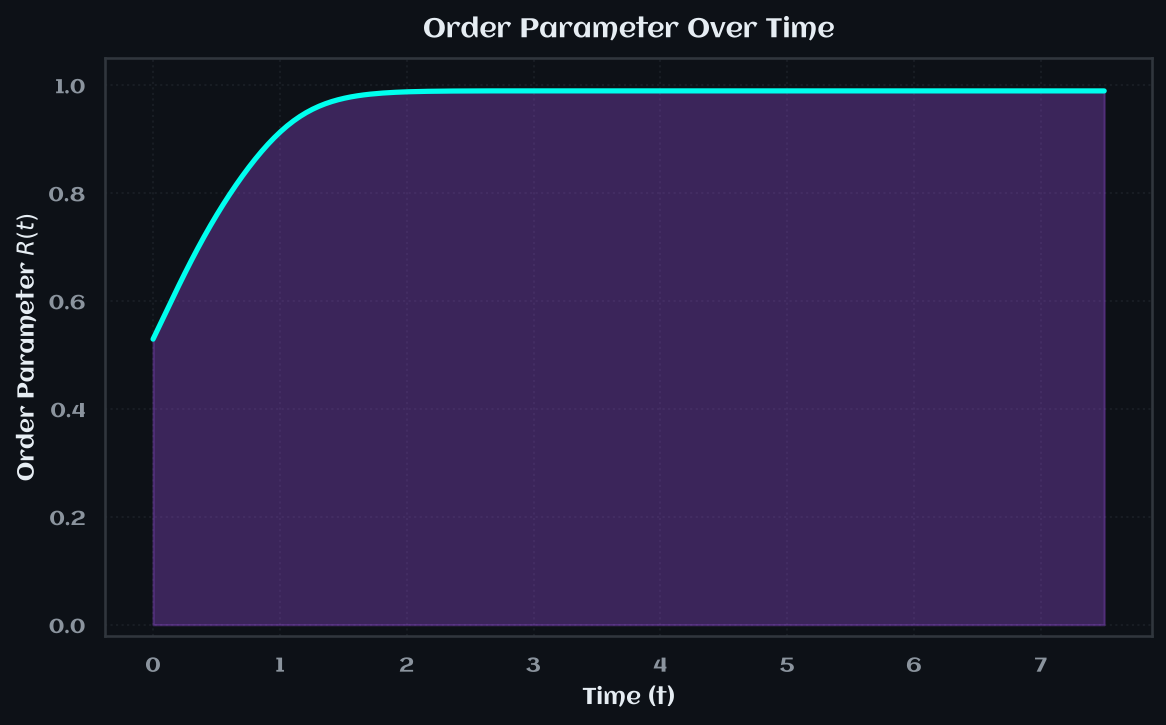

✅ plot_order_parameter() — passed


In [14]:
# --- plot_order_parameter ---
# Shows the synchronization metric r(t) over time

print("📈 Testing plot_order_parameter()...")
r = compute_order_parameter(ds["theta"])
plot_order_parameter(ds["time"], r)
print("✅ plot_order_parameter() — passed")

📈 Testing plot_distributions()...


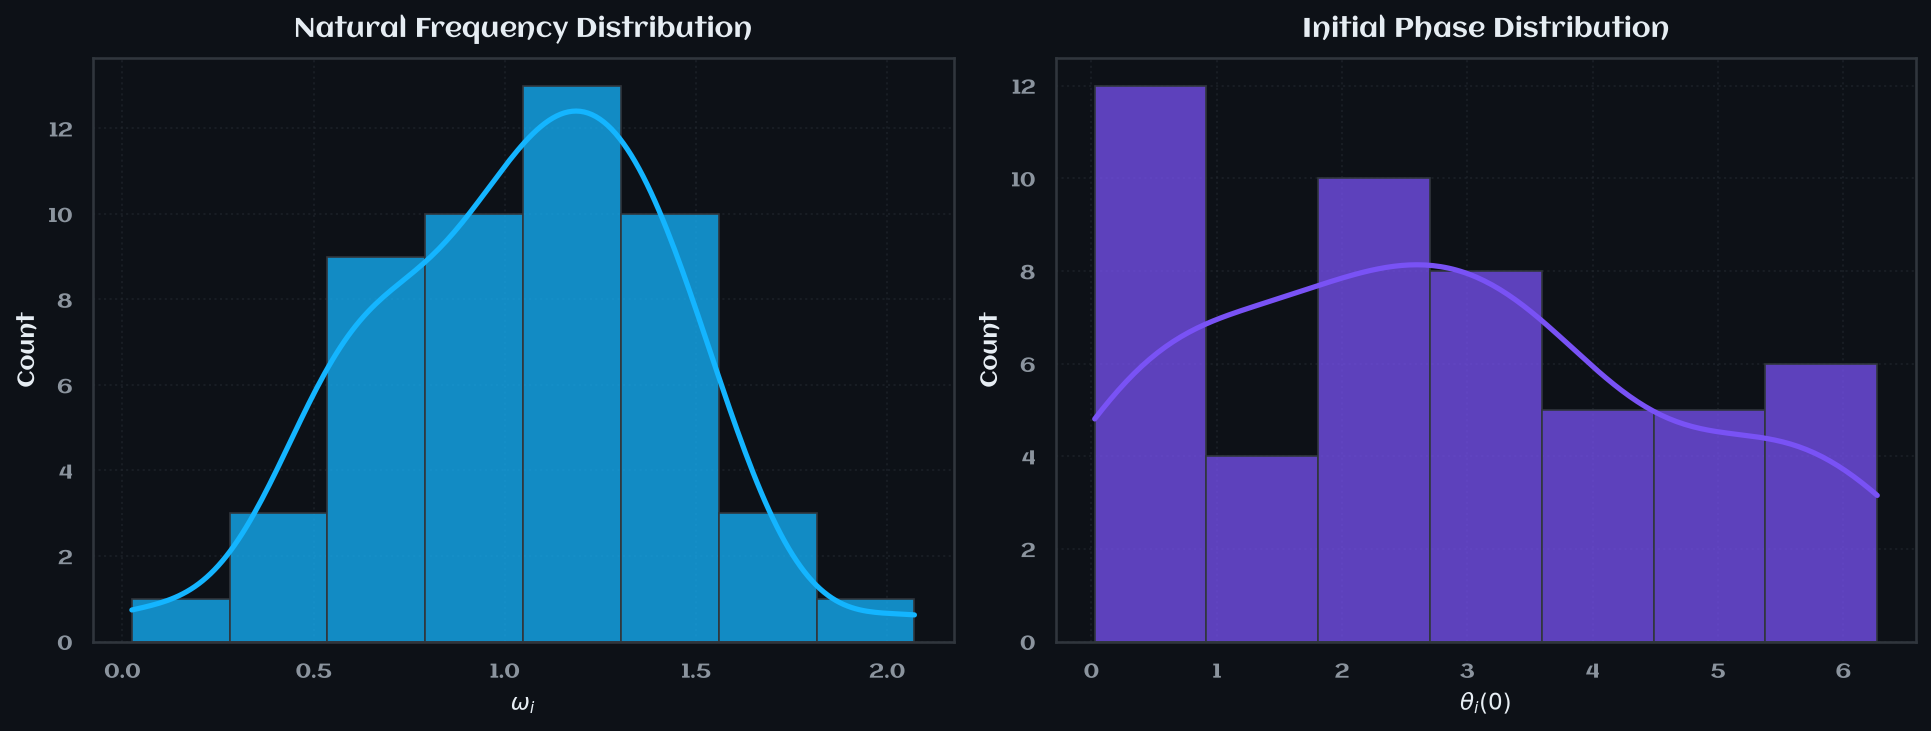

✅ plot_distributions() — passed


In [15]:
# --- plot_distributions ---
# Shows histograms of natural frequencies and initial phases

print("📈 Testing plot_distributions()...")
N = 50
omega = np.random.default_rng(42).normal(1.0, 0.5, N)
theta_0 = np.random.default_rng(43).uniform(0, 2 * np.pi, N)
plot_distributions(omega, theta_0)
print("✅ plot_distributions() — passed")

📈 Testing plot_network()...


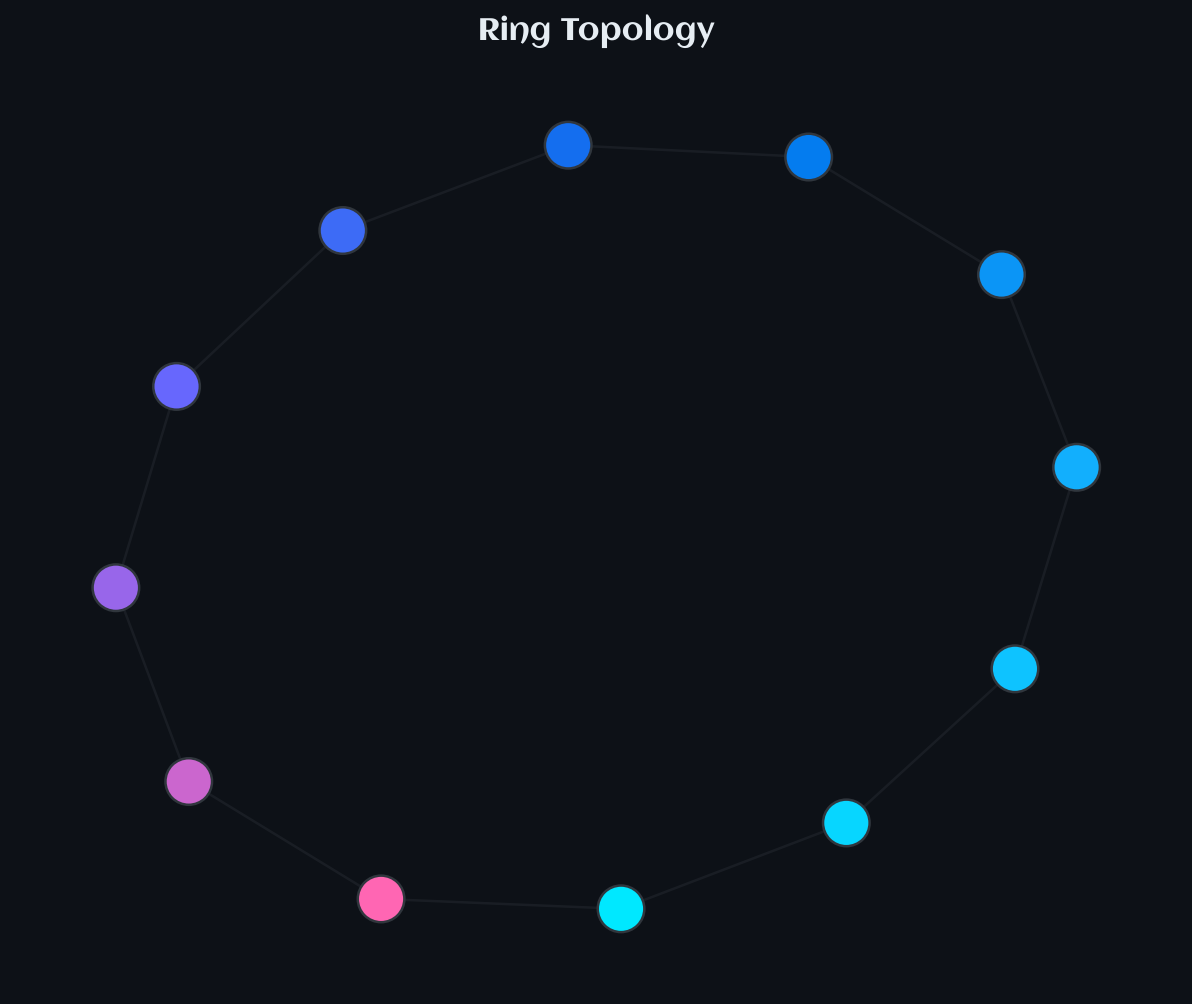

✅ plot_network() — ring topology passed


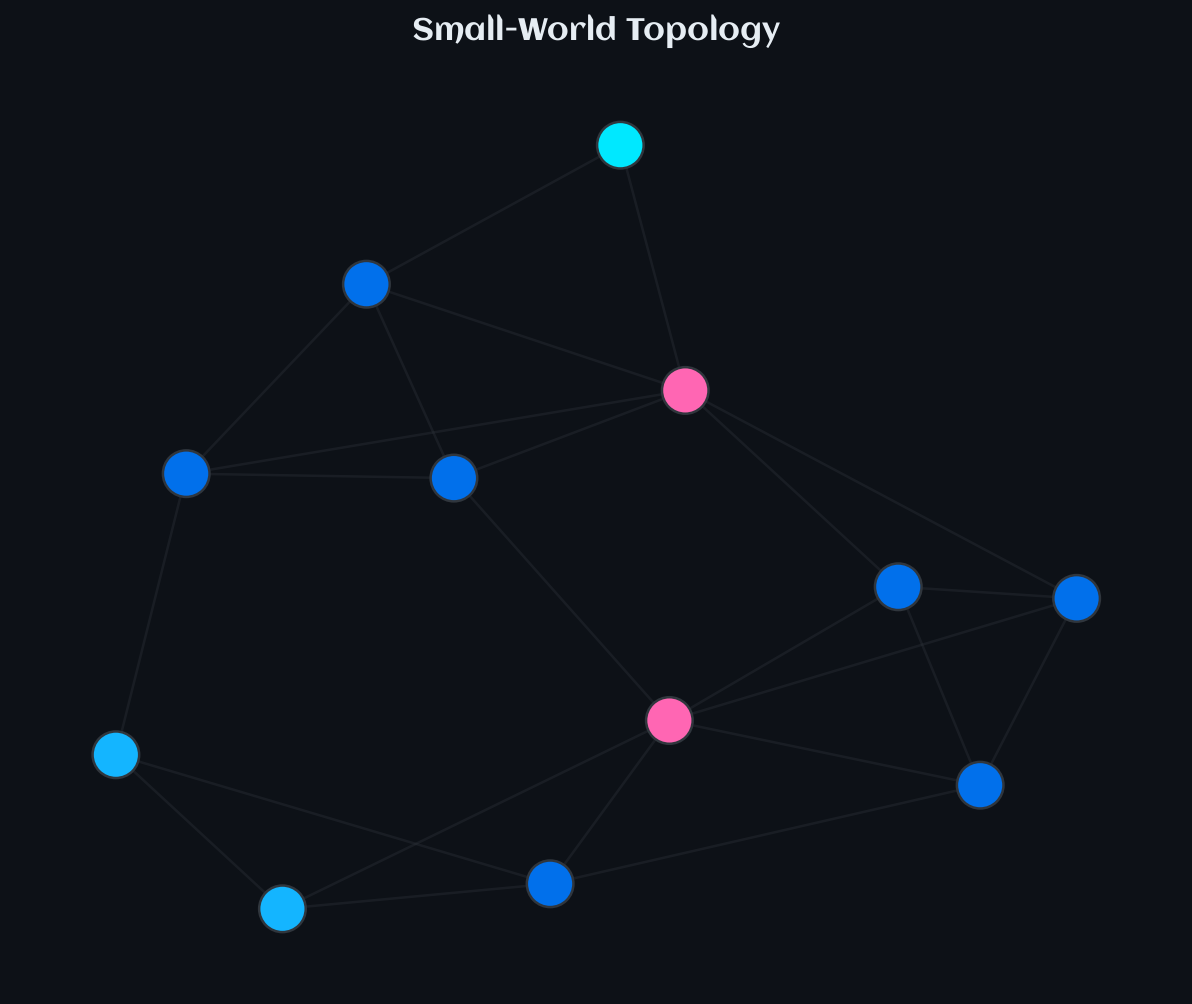

✅ plot_network() — small-world topology passed


In [16]:
# --- plot_network ---
# Visualizes the network topology (adjacency matrix as a graph)

print("📈 Testing plot_network()...")
N = 12

# Test with a ring topology
adj_ring = load_topology("ring", n=N)
plot_network(adj_ring, title="Ring Topology")
print("✅ plot_network() — ring topology passed")

# Test with a small-world topology
adj_sw = load_topology("small_world", n=N, k=4, p=0.1)
plot_network(adj_sw, title="Small-World Topology")
print("✅ plot_network() — small-world topology passed")

📈 Testing plot_fluid_vorticity()...


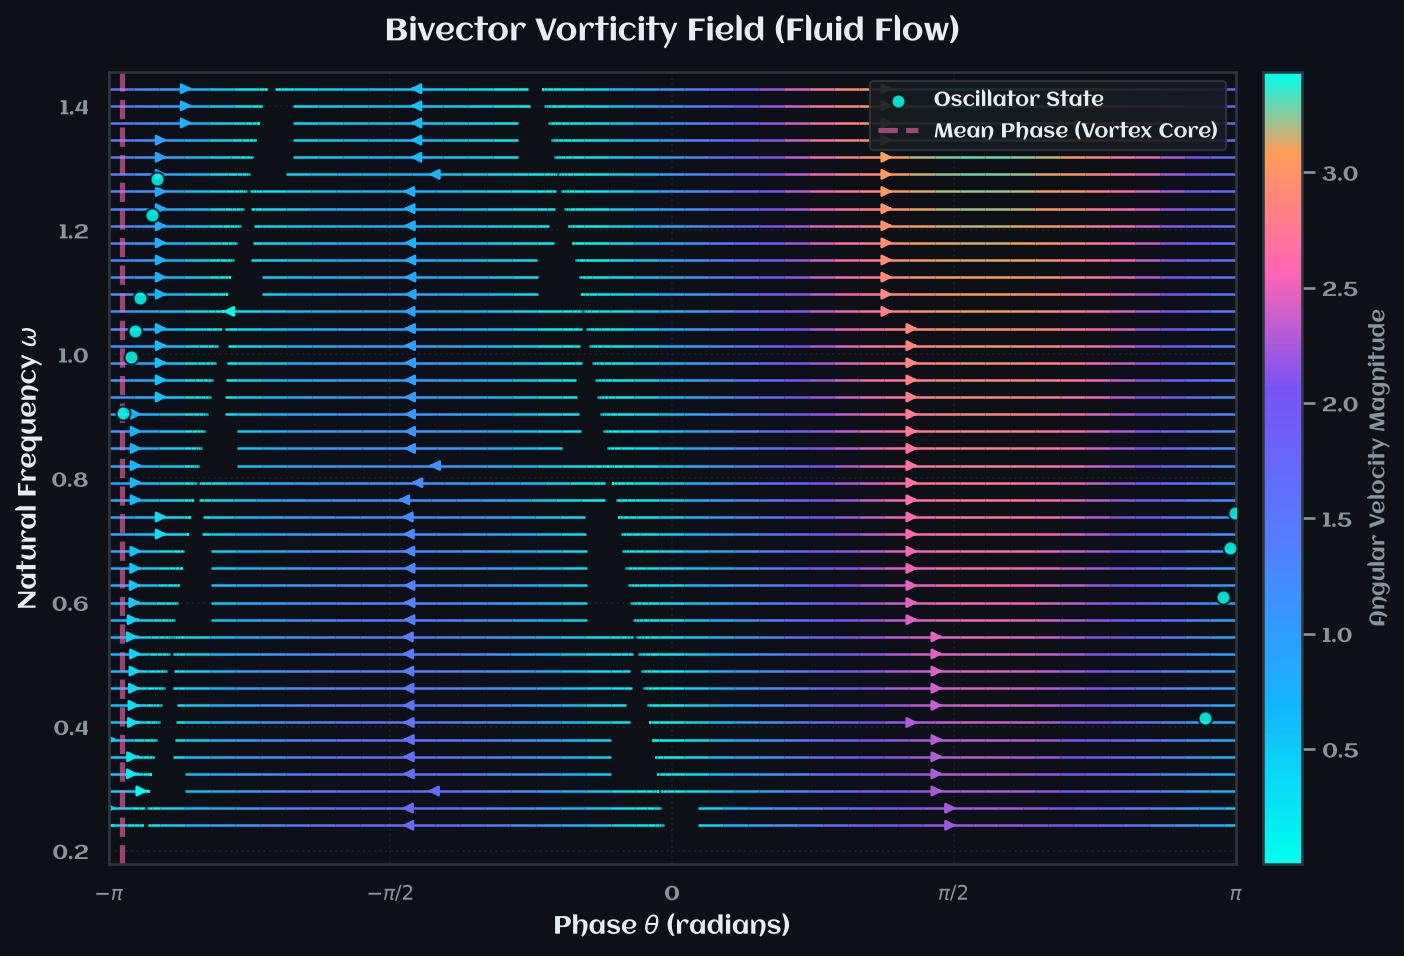

✅ plot_fluid_vorticity() — passed


In [17]:
# --- plot_fluid_vorticity ---
# Visualizes the phase velocity field (how fast each oscillator is rotating)

print("📈 Testing plot_fluid_vorticity()...")
N = 10
omega = np.random.default_rng(42).normal(1.0, 0.3, N)
ds = generate_kuramoto_dataset(
    n_oscillators=N, natural_frequencies=omega, coupling=2.0,
    timesteps=100, dt=0.05, seed=42, solver="rk45",
)

# plot_fluid_vorticity requires K (coupling strength) as a positional arg
# Pass final phase snapshot ds["theta"][-1] or trajectory ds["theta"]
K = 2.0
plot_fluid_vorticity(ds["theta"][-1], omega, K)
print("✅ plot_fluid_vorticity() — passed")

📈 Testing plot_autocorrelation()...


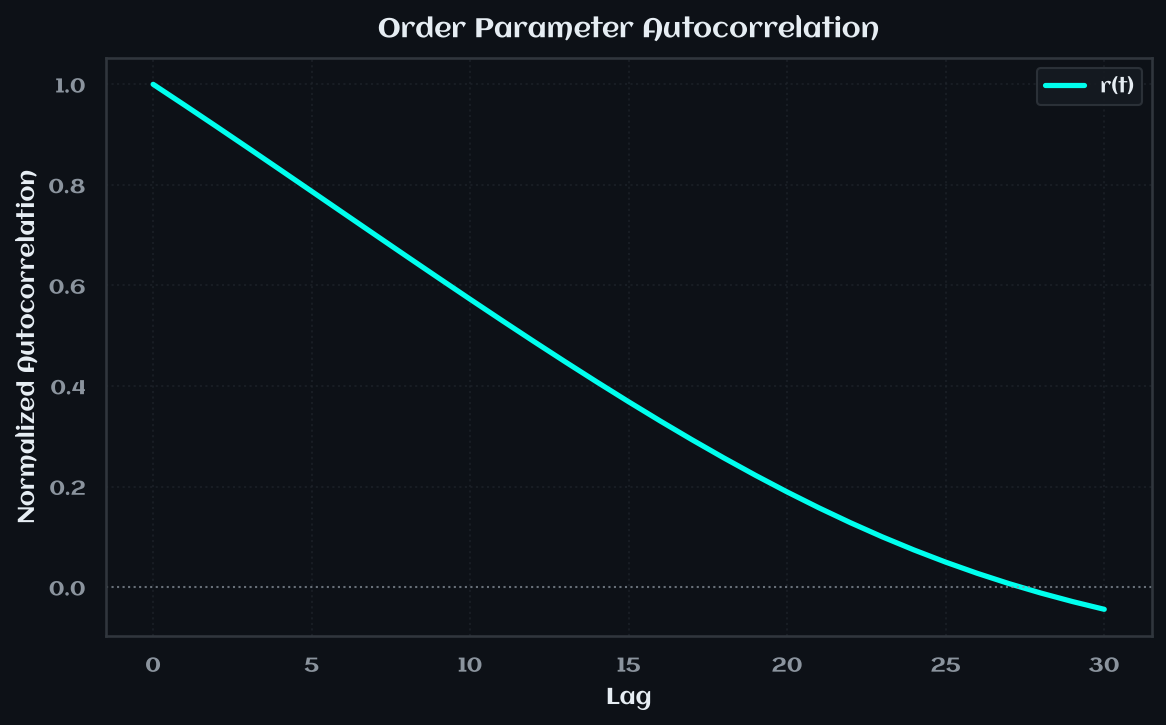

✅ plot_autocorrelation() — passed


In [18]:
# --- plot_autocorrelation ---
# Shows how the order parameter correlates with itself at different time lags

print("📈 Testing plot_autocorrelation()...")
r = compute_order_parameter(ds["theta"])
lags, autocorr = compute_order_parameter_autocorrelation(r, max_lag=30)
# plot_autocorrelation expects a Dict[str, Tuple[lags, autocorr]]
plot_autocorrelation({"r(t)": (lags, autocorr)})
print("✅ plot_autocorrelation() — passed")

📈 Testing Fourier plot functions...


/Users/lshriver/PycharmProjects/kuramoto-benchmark-suite/src/kuramoto/analysis/spectral.py:85: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 200, using nperseg = 200
  f, pxx = welch(fluctuations, fs=fs, axis=0, **kwargs)


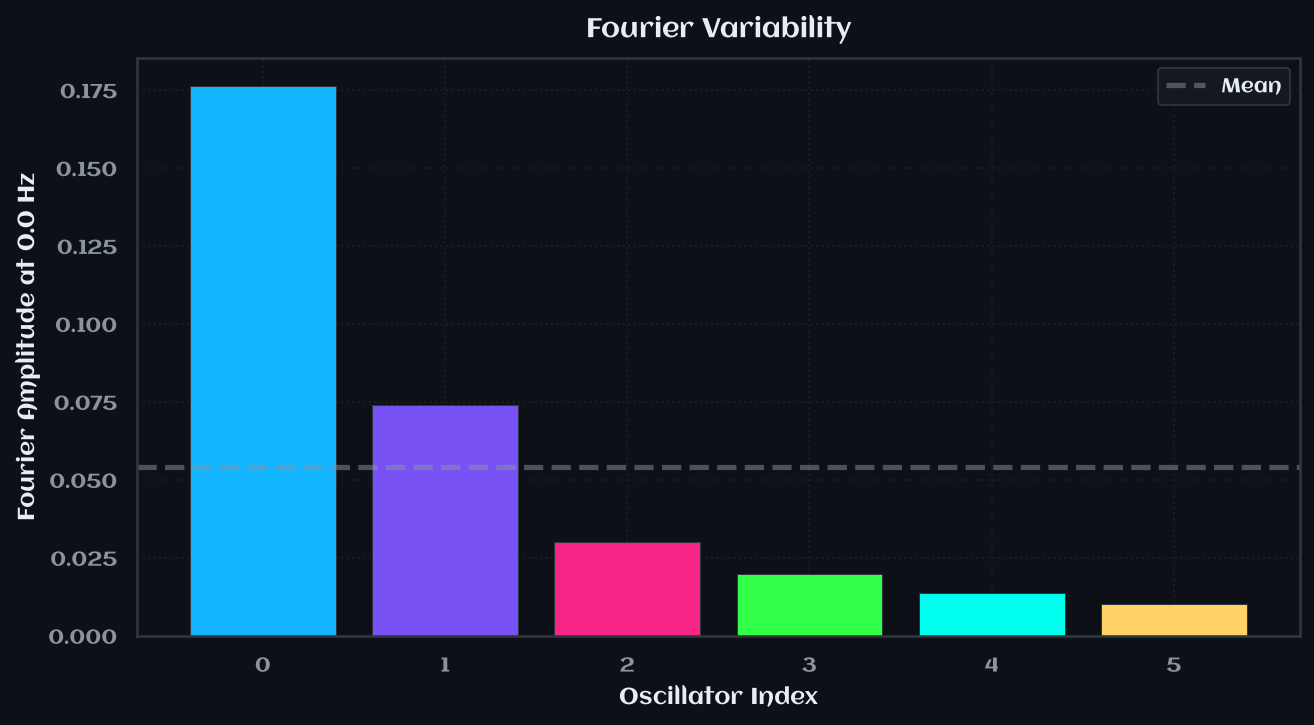

✅ plot_fourier_variability() — passed


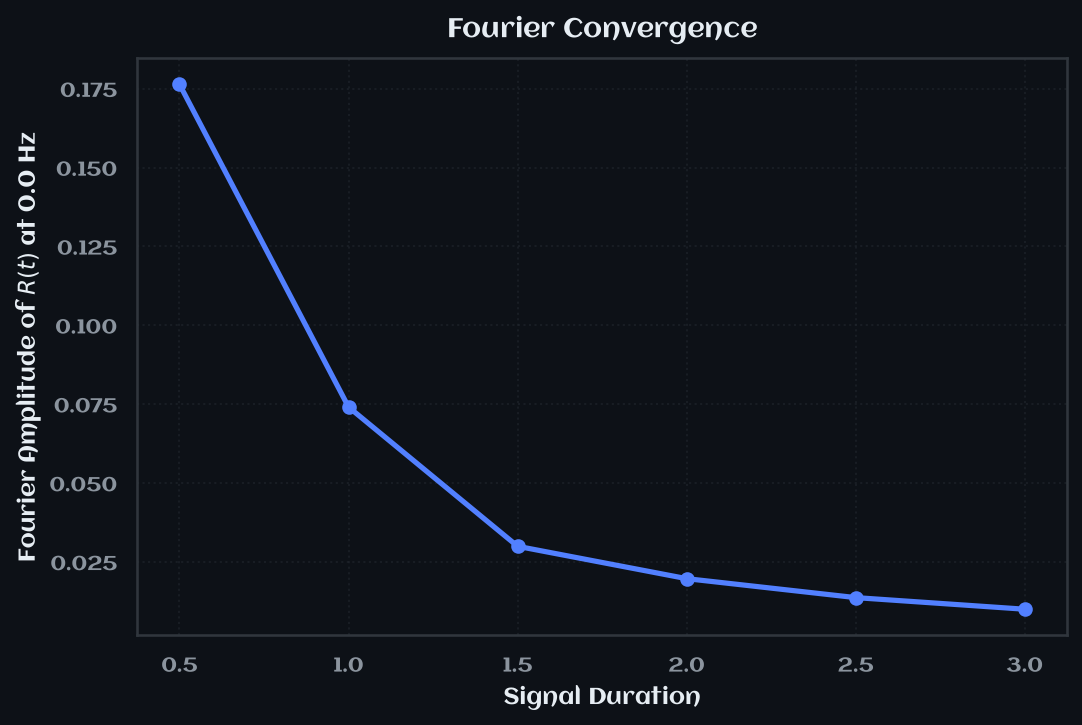

✅ plot_fourier_convergence() — passed


In [19]:
# --- plot_fourier_variability and plot_fourier_convergence ---
# Fourier amplitude bar chart and convergence line plot

print("📈 Testing Fourier plot functions...")

# Generate data at different coupling strengths for convergence plot
K_values = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
amplitudes = []
durations = []

for K in K_values:
    ds = generate_kuramoto_dataset(
        n_oscillators=10, natural_frequencies=np.ones(10), coupling=K,
        timesteps=200, dt=0.05, seed=42, solver="rk45",
    )
    r = compute_order_parameter(ds["theta"])
    fs = 1.0 / 0.05
    freqs, psd = compute_psd(r, fs)
    amplitudes.append(psd.max())
    durations.append(K)

amplitudes = np.array(amplitudes)

# Fourier variability (bar chart of amplitudes)
plot_fourier_variability(amplitudes)
print("✅ plot_fourier_variability() — passed")

# Fourier convergence (line plot)
plot_fourier_convergence(durations, amplitudes)
print("✅ plot_fourier_convergence() — passed")

📈 Testing PSD plot functions...


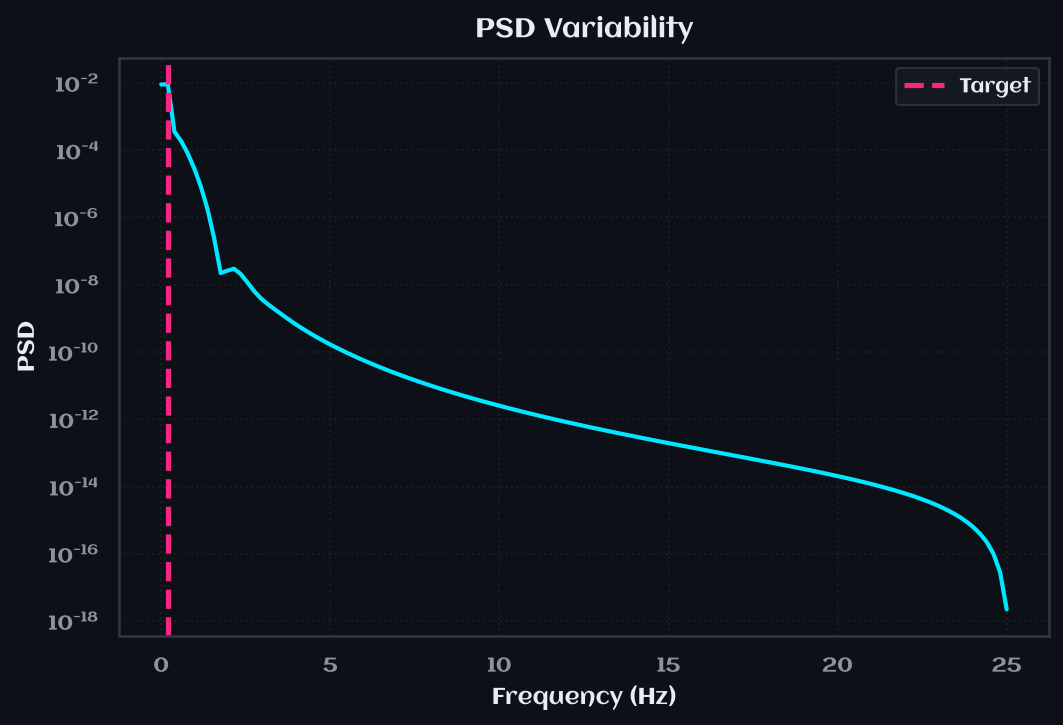

✅ plot_psd_variability() — passed


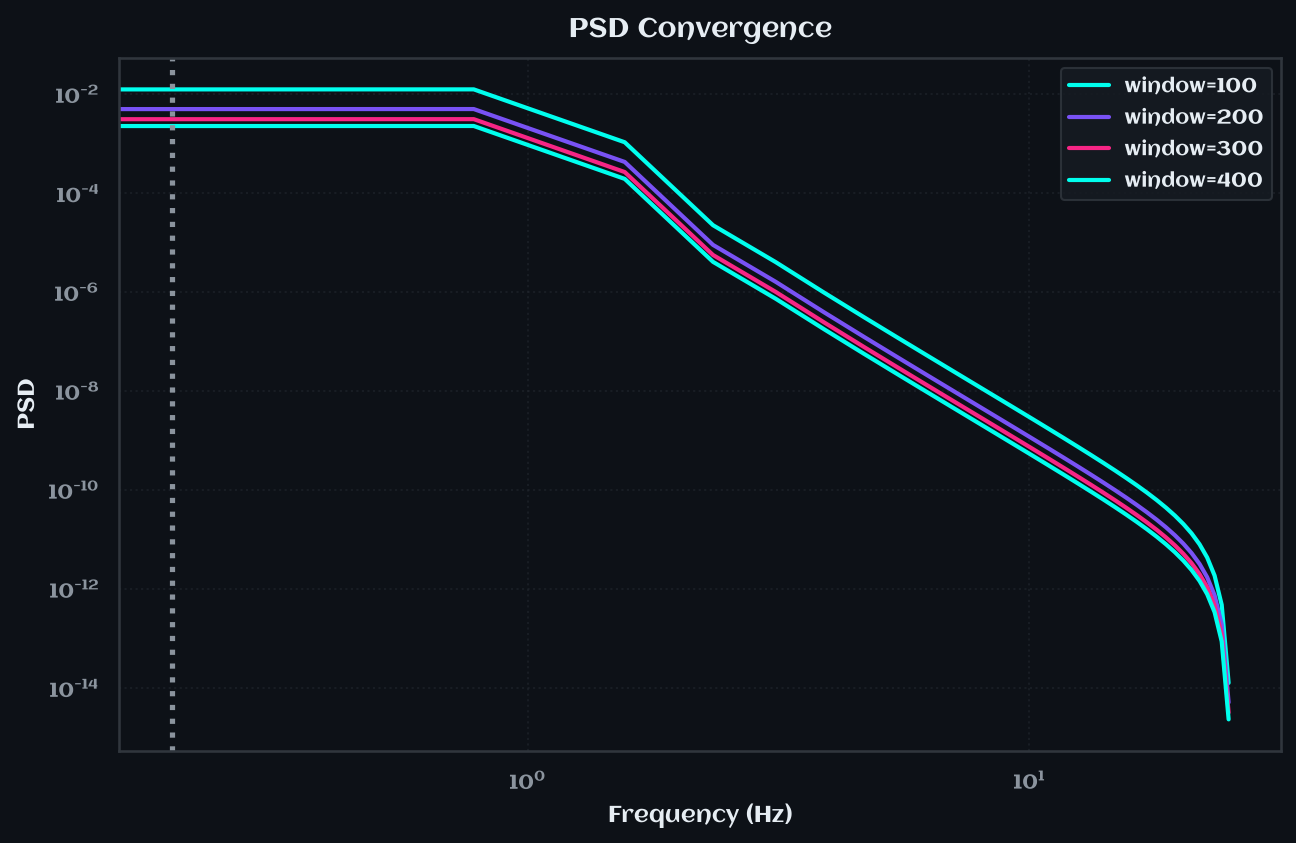

✅ plot_psd_convergence() — passed


In [20]:
# --- plot_psd_variability and plot_psd_convergence ---
# PSD line plot with target marker and multi-window convergence

print("📈 Testing PSD plot functions...")

N = 15
omega = np.random.default_rng(42).normal(1.0, 0.3, N)
ds = generate_kuramoto_dataset(
    n_oscillators=N, natural_frequencies=omega, coupling=3.0,
    timesteps=400, dt=0.02, seed=42, solver="rk45",
)

r = compute_order_parameter(ds["theta"])
fs = 1.0 / 0.02
freqs, psd = compute_psd(r, fs)

# PSD variability (target_freq is required)
target_freq = freqs[np.argmax(psd)]
plot_psd_variability(freqs, psd, target_freq=target_freq)
print("✅ plot_psd_variability() — passed")

# PSD convergence (multiple windows)
psd_data = {}
for window in [100, 200, 300, 400]:
    r_window = compute_order_parameter(ds["theta"][:window])
    freqs_win, psd_window = compute_psd(r_window, fs, nperseg=64)
    psd_data[f"window={window}"] = psd_window

# plot_psd_convergence requires target_freq
plot_psd_convergence(freqs_win, psd_data, target_freq=target_freq)
print("✅ plot_psd_convergence() — passed")

📈 Testing plot_semantic_colormaps()...


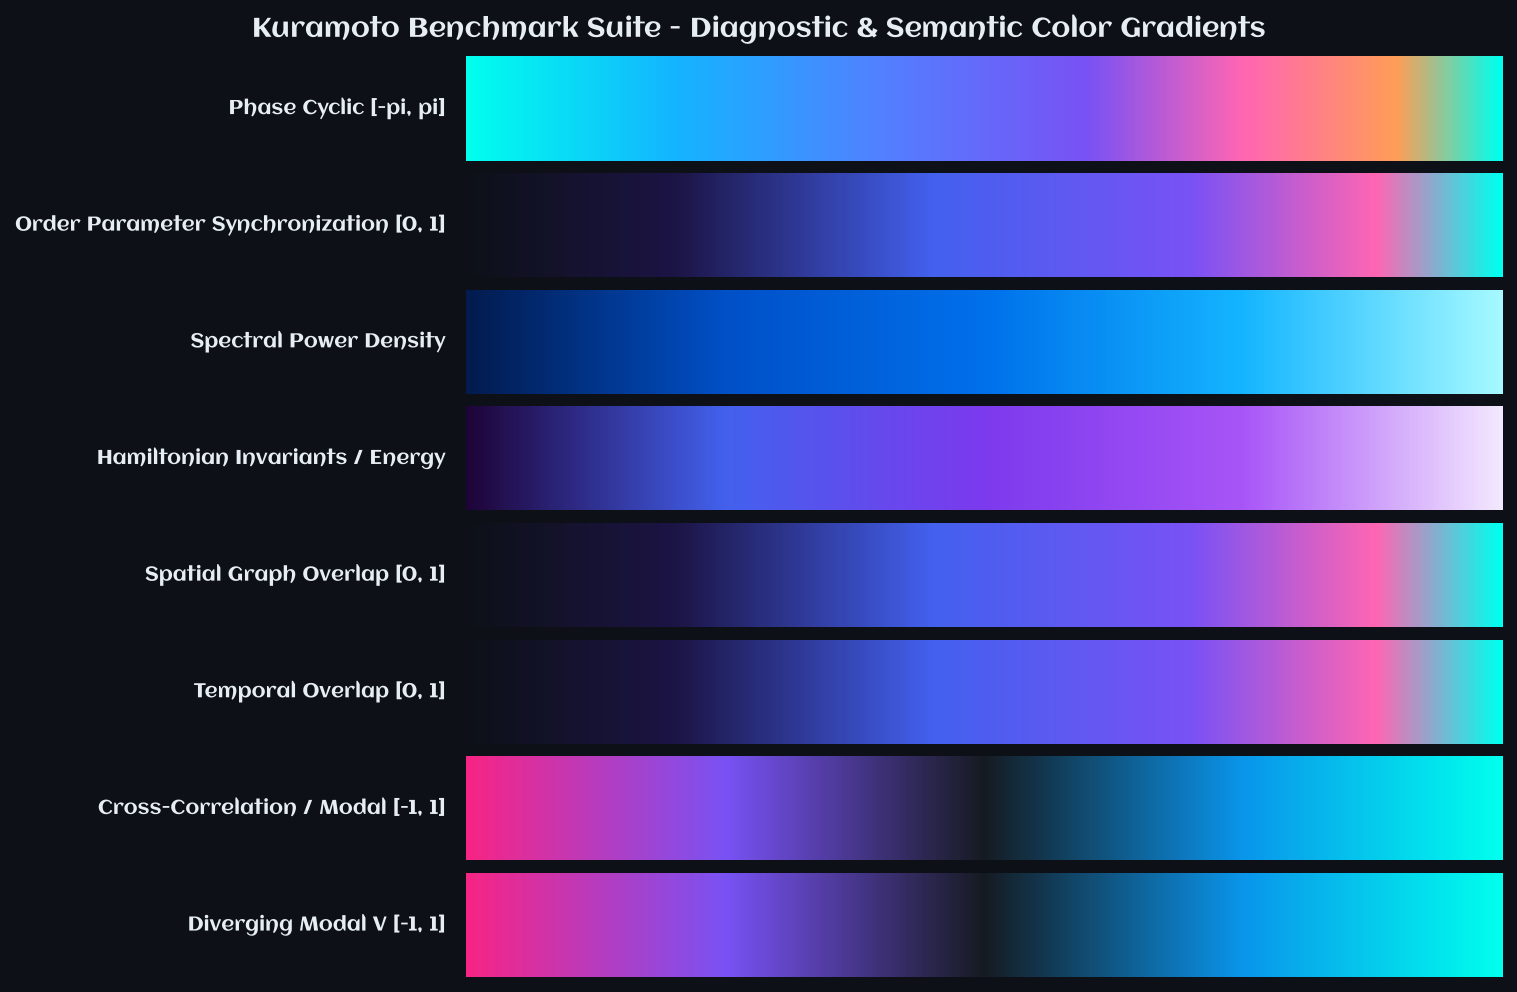

✅ plot_semantic_colormaps() — passed


In [21]:
# --- plot_semantic_colormaps ---
# Renders all semantic colormaps as a single figure

print("📈 Testing plot_semantic_colormaps()...")
fig = plot_semantic_colormaps(out_path=None)
plt.show()
print("✅ plot_semantic_colormaps() — passed")

## 9️⃣ CLI Colors — Current Output Styling

### 📖 Educational Note

The CLI uses **Click** for command-line interface construction. Click provides built-in color support via `click.secho()` with named foreground colors.

#### Current CLI Color Usage
The CLI currently uses direct `click.secho()` calls with colors like:
- `fg="bright_blue"` — Headers and titles
- `fg="green"` / `fg="bright_green"` — Success messages
- `fg="blue"` — Informational messages
- `fg="yellow"` — Warnings
- `fg="red"` — Errors

#### Planned Improvements (from `cli_color_styling.md`)
The plan is to create semantic wrapper functions:
- `cli_info("...")` → blue
- `cli_success("...")` → bright_green
- `cli_warning("...")` → yellow
- `cli_error("...")` → red
- `cli_purple("...")` → bright_magenta (for visual/attention support)

#### Click Color Limitations
Click supports a limited palette: black, red, green, yellow, blue, magenta, cyan, white (and bright variants). True RGB colors require ANSI escape codes or the `rich` library.

In [22]:
# Demonstrate current CLI color output
print("🎨 Current CLI Color Output:\n")

print("--- Direct click.secho() calls (current approach) ---\n")

click.secho("  Header text", fg="bright_blue", bold=True)
click.secho("  Information message", fg="blue")
click.secho("  Success message", fg="bright_green")
click.secho("  Warning message", fg="yellow")
click.secho("  Error message", fg="red")
click.secho("  Accent / purple-like message", fg="bright_magenta")
click.secho("  Default text", fg=None)

print("\n--- Planned semantic wrappers (future approach) ---\n")
print("  (These would replace direct click.secho() calls)")
print()
print("  cli_info('Parsing configuration...')        → blue")
print("  cli_success('Dataset saved.')               → bright_green")
print("  cli_warning('Symmetry tracking requires rotor solver.') → yellow")
print("  cli_error('Missing configuration file.')    → red")
print("  cli_purple('Visualizing network...')        → bright_magenta")

# Show the planned color mapping
STYLE_COLORS = {
    "info": "blue",
    "success": "bright_green",
    "warning": "yellow",
    "error": "red",
    "accent": "bright_magenta",
    "purple": "bright_magenta",
}

print("\n--- Planned STYLE_COLORS mapping ---")
for style_name, click_color in STYLE_COLORS.items():
    click.secho(f"  {style_name:10s} → ", fg=click_color, bold=True)
    click.secho(f"{'':12s}    Example message", fg=click_color)

print("\n💡 Note: 'purple' is not a valid Click color name.")
print("   Use 'magenta' or 'bright_magenta' instead.")

🎨 Current CLI Color Output:

--- Direct click.secho() calls (current approach) ---

  Header text
  Information message
  Success message
  Warning message
  Error message
  Accent / purple-like message
  Default text

--- Planned semantic wrappers (future approach) ---

  (These would replace direct click.secho() calls)

  cli_info('Parsing configuration...')        → blue
  cli_success('Dataset saved.')               → bright_green
  cli_warning('Symmetry tracking requires rotor solver.') → yellow
  cli_error('Missing configuration file.')    → red
  cli_purple('Visualizing network...')        → bright_magenta

--- Planned STYLE_COLORS mapping ---
  info       → 
                Example message
  success    → 
                Example message
  warning    → 
                Example message
  error      → 
                Example message
  accent     → 
                Example message
  purple     → 
                Example message

💡 Note: 'purple' is not a valid Click color name.
   

In [23]:
# Run the actual CLI to see its colored output
!kuramoto --help

Usage: kuramoto [OPTIONS] [COMMAND] [ARGS]...

  ---------------   KURAMOTO   --------------------

  A tool for simulating and analyzing Kuramoto oscillator networks. Inspired
  by 'satis' for spectral analysis.

Options:
  --help  Show this message and exit.

Commands:
  datasetforbeginners  Copy a set of signals to train using the suite.
  distributions        Visualize frequency and phase distributions.
  fourierconvergence   Plot discrete Fourier transform convergence.
  fouriervariability   Plot the Fourier variability diagnostic results.
  generate             Generate a dataset from a JSON configuration file.
  network              Visualize the oscillator network structure.
  psdconvergence       Plot the PSD convergence diagnostic results.
  psdvariability       Plot the spectral energy at the target frequency.
  time                 Plot the temporal signal and its time-average.


## 🔟 Network Topologies

### 📖 Educational Note

The **network topology** determines which oscillators are coupled. The adjacency matrix $A_{ij}$ encodes this:
- $A_{ij} = 1$ if oscillators $i$ and $j$ are connected
- $A_{ij} = 0$ otherwise

#### Available Topologies
| Topology | Description | Critical $K_c$ |
|----------|-------------|----------------|
| `complete` | Every oscillator connected to every other | $K_c = 2 / \langle k \rangle$ |
| `ring` | Each oscillator connected to nearest neighbors | Higher $K_c$ (sparse) |
| `small_world` | Ring with random rewiring (Watts-Strogatz) | Between ring and complete |
| `erdos_renyi` | Random graph with edge probability $p$ | Depends on $p$ |
| `bipartite` | Two groups; connections only between groups | Unique dynamics |
| `tree_of_life` | Hierarchical tree structure | High $K_c$ |

The topology directly affects the synchronization threshold and the system's dynamics.

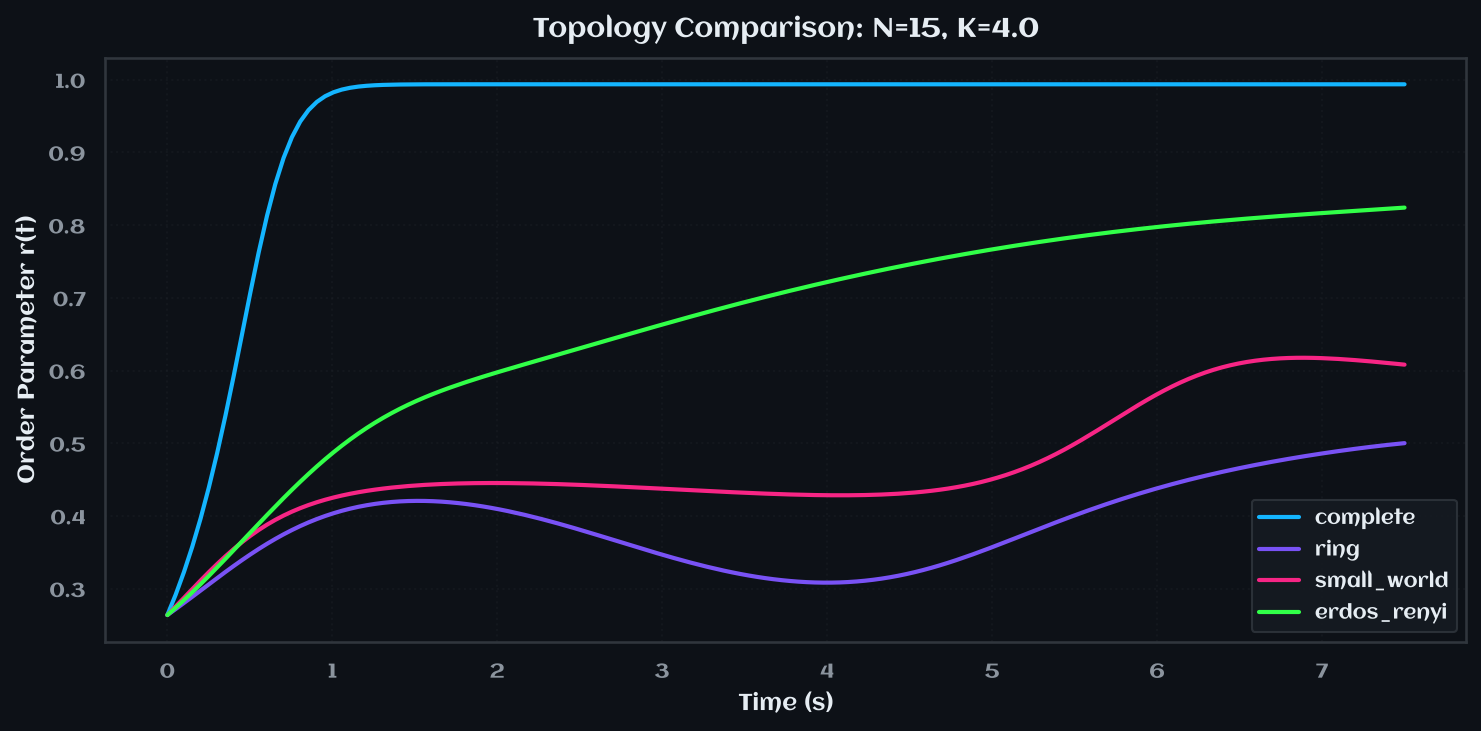

📊 Final synchronization by topology:
   complete       : r(final) = 0.9937, r(mean) = 0.9486
   ring           : r(final) = 0.5002, r(mean) = 0.3862
   small_world    : r(final) = 0.7777, r(mean) = 0.6592
   erdos_renyi    : r(final) = 0.3204, r(mean) = 0.4028


In [24]:
# Compare synchronization across different topologies
N = 15
omega = np.random.default_rng(42).normal(1.0, 0.5, N)
K = 4.0
timesteps = 150
dt = 0.05

topologies = ["complete", "ring", "small_world", "erdos_renyi"]
topology_kwargs = {
    "complete": {},
    "ring": {},
    "small_world": {"k": 4, "p": 0.1},
    "erdos_renyi": {"p": 0.3},
}

fig, ax = plt.subplots(figsize=(10, 5))

for topo in topologies:
    ds = generate_kuramoto_dataset(
        n_oscillators=N, natural_frequencies=omega, coupling=K,
        timesteps=timesteps, dt=dt, seed=42, solver="rk45",
        topology=topo, topology_kwargs=topology_kwargs[topo],
    )
    r = compute_order_parameter(ds["theta"])
    ax.plot(ds["time"], r, label=topo, linewidth=2)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Order Parameter r(t)")
ax.set_title(f"Topology Comparison: N={N}, K={K}")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print final r values
print("📊 Final synchronization by topology:")
for topo in topologies:
    ds = generate_kuramoto_dataset(
        n_oscillators=N, natural_frequencies=omega, coupling=K,
        timesteps=timesteps, dt=dt, seed=42, solver="rk45",
        topology=topo, topology_kwargs=topology_kwargs[topo],
    )
    r = compute_order_parameter(ds["theta"])
    print(f"   {topo:15s}: r(final) = {r[-1]:.4f}, r(mean) = {r.mean():.4f}")

## 1️⃣1️⃣ Summary — What This Notebook Validates

### ✅ What We Tested

This notebook serves as a **living regression test** and **visual baseline** for the Kuramoto Benchmark Suite. Here's what it covers:

#### Numerical Integration
- [x] **RK45 solver** — Adaptive Runge-Kutta, 5th order accuracy
- [x] **Euler solver** — Fixed-step, 1st order (via RotorSolver)
- [x] **Euler-fast solver** — Order-parameter-based Euler
- [x] **Euler-geometric solver** — Pure GA bivector torque
- [x] **Accuracy comparison** — RK45 vs Euler with coarse dt

#### Geometric Algebra
- [x] **Cl(2,0) algebra** — Basis vectors, bivectors, geometric product
- [x] **Rotor representation** — Phase encoding and extraction
- [x] **Norm invariants** — Rotor norm preservation during simulation
- [x] **Rotation action** — R · v · ~R rotates vectors correctly
- [x] **Lie symmetry** — U(1) phase invariance tracking

#### Order Parameter & Spectral Analysis
- [x] **Order parameter r(t)** — Synchronization metric
- [x] **Autocorrelation** — Memory of synchronization state
- [x] **PSD** — Power spectral density
- [x] **Harmonic analysis** — Frequency decomposition
- [x] **Sync transition detection** — Critical K identification

#### Visualization System (Pre-Refactor Baseline)
- [x] **Design tokens** — THEME_BG, TEXT_PRIMARY, GOLDEN_RATIO, etc.
- [x] **Color palettes** — PROJECT_COLORS, SOLVER_COLORS, COMPARISON_PALETTE
- [x] **8 semantic colormaps** — phase, order_parameter, spectral_density, etc.
- [x] **12+ plot functions** — All exercised and visually verified
- [x] **GRADIENTS dictionary** — Gradient bar rendering

#### CLI Colors
- [x] **Current color usage** — Direct click.secho() calls documented
- [x] **Planned semantic wrappers** — STYLE_COLORS mapping shown
- [x] **Click color limitations** — Purple → bright_magenta noted

#### Network Topologies
- [x] **Complete, ring, small-world, Erdős-Rényi** — Compared side-by-side

### 📋 Before Implementing the Markdown Plans

1. **Viz Refactor** (`viz_refactor_plan.md`): Rerun this notebook after each phase to catch regressions. Every plot function, colormap, and design token should produce identical output.
2. **CLI Styling** (`cli_color_styling.md`): After implementing `cli_info()`, `cli_success()`, etc., rerun the CLI color section to verify the semantic wrappers work.

### 🎓 Key Takeaways

1. **RK45 is the gold standard** for accuracy; Euler methods trade accuracy for simplicity and GA compatibility
2. **Geometric algebra** provides a natural representation for phase oscillators that preserves U(1) symmetry
3. **The order parameter r(t)** is the single most important diagnostic — it tells you everything about synchronization
4. **Spectral analysis** reveals hidden frequency structure and transition points
5. **The visualization system** is comprehensive but monolithic — the planned refactor will improve maintainability
6. **CLI colors** are functional but could benefit from semantic wrappers for readability

In [25]:
# Final sanity check — verify everything is importable and working
print("🔍 Final Import Verification:\n")

checks = [
    ("kuramoto.api", "generate_kuramoto_dataset"),
    ("kuramoto.solvers", "solve_kuramoto"),
    ("kuramoto.solvers", "RotorSolver"),
    ("kuramoto.order_parameter", "compute_order_parameter"),
    ("kuramoto.order_parameter", "compute_order_parameter_autocorrelation"),
    ("kuramoto.order_parameter", "track_lie_symmetries"),
    ("kuramoto.analysis.spectral", "compute_psd"),
    ("kuramoto.analysis.spectral", "harmonic_analysis"),
    ("kuramoto.analysis.spectral", "detect_sync_transition"),
    ("kuramoto.analysis.viz", "set_style"),
    ("kuramoto.analysis.viz", "plot_time_series"),
    ("kuramoto.analysis.viz", "plot_order_parameter"),
    ("kuramoto.analysis.viz", "plot_network"),
    ("kuramoto.analysis.viz", "plot_distributions"),
    ("kuramoto.analysis.viz", "plot_fluid_vorticity"),
    ("kuramoto.analysis.viz", "plot_autocorrelation"),
    ("kuramoto.analysis.viz", "plot_semantic_colormaps"),
    ("kuramoto.analysis.viz", "PHASE_CMAP"),
    ("kuramoto.analysis.viz", "ORDER_PARAMETER_CMAP"),
    ("kuramoto.analysis.viz", "PROJECT_COLORS"),
    ("kuramoto.analysis.viz", "SOLVER_COLORS"),
    ("kuramoto.analysis.viz", "GRADIENTS"),
    ("kuramoto.topologies", "load_topology"),
    ("kuramoto.solver_types", "SOLVER_ALIASES"),
    ("kuramoto.solver_types", "is_rotor_or_euler"),
]

passed = 0
failed = 0
for module, symbol in checks:
    try:
        mod = __import__(module, fromlist=[symbol])
        getattr(mod, symbol)
        print(f"  ✅ {module}.{symbol}")
        passed += 1
    except (ImportError, AttributeError) as e:
        print(f"  ❌ {module}.{symbol} — {e}")
        failed += 1

print(f"\n{'='*50}")
print(f"✅ {passed}/{len(checks)} imports verified")
if failed > 0:
    print(f"❌ {failed} imports failed")
else:
    print("🎉 All imports working — notebook baseline established!")

🔍 Final Import Verification:

  ✅ kuramoto.api.generate_kuramoto_dataset
  ✅ kuramoto.solvers.solve_kuramoto
  ✅ kuramoto.solvers.RotorSolver
  ✅ kuramoto.order_parameter.compute_order_parameter
  ✅ kuramoto.order_parameter.compute_order_parameter_autocorrelation
  ✅ kuramoto.order_parameter.track_lie_symmetries
  ✅ kuramoto.analysis.spectral.compute_psd
  ✅ kuramoto.analysis.spectral.harmonic_analysis
  ✅ kuramoto.analysis.spectral.detect_sync_transition
  ✅ kuramoto.analysis.viz.set_style
  ✅ kuramoto.analysis.viz.plot_time_series
  ✅ kuramoto.analysis.viz.plot_order_parameter
  ✅ kuramoto.analysis.viz.plot_network
  ✅ kuramoto.analysis.viz.plot_distributions
  ✅ kuramoto.analysis.viz.plot_fluid_vorticity
  ✅ kuramoto.analysis.viz.plot_autocorrelation
  ✅ kuramoto.analysis.viz.plot_semantic_colormaps
  ✅ kuramoto.analysis.viz.PHASE_CMAP
  ✅ kuramoto.analysis.viz.ORDER_PARAMETER_CMAP
  ✅ kuramoto.analysis.viz.PROJECT_COLORS
  ✅ kuramoto.analysis.viz.SOLVER_COLORS
  ✅ kuramoto.analysis